In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
    precision_recall_curve,
)


In [2]:
import kagglehub
# Download
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print("Path to dataset files:", path)

Path to dataset files: /mnt/data/olist_data


In [3]:
files = os.listdir(path)
for i in range(len(files)):
  print(files[i])
print("Доступные файлы:", files)


olist_customers_dataset.csv
olist_sellers_dataset.csv
olist_order_reviews_dataset.csv
product_category_name_translation.csv
olist_orders_dataset.csv
olist_order_payments_dataset.csv
olist_products_dataset.csv
olist_order_items_dataset.csv
olist_geolocation_dataset.csv
Доступные файлы: ['olist_customers_dataset.csv', 'olist_sellers_dataset.csv', 'olist_order_reviews_dataset.csv', 'product_category_name_translation.csv', 'olist_orders_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_products_dataset.csv', 'olist_order_items_dataset.csv', 'olist_geolocation_dataset.csv']


In [4]:
orders = pd.read_csv(os.path.join(path, "olist_orders_dataset.csv"))
customers = pd.read_csv(os.path.join(path, "olist_customers_dataset.csv"))
products = pd.read_csv(os.path.join(path, "olist_products_dataset.csv"))
sellers = pd.read_csv(os.path.join(path, "olist_sellers_dataset.csv"))
order_items = pd.read_csv(os.path.join(path, "olist_order_items_dataset.csv"))
order_payments = pd.read_csv(os.path.join(path, "olist_order_payments_dataset.csv"))
order_reviews = pd.read_csv(os.path.join(path, "olist_order_reviews_dataset.csv"))
geolocation = pd.read_csv(os.path.join(path, "olist_geolocation_dataset.csv"))


In [5]:
print(orders.head())

                           order_id  ... order_estimated_delivery_date
0  e481f51cbdc54678b7cc49136f2d6af7  ...           2017-10-18 00:00:00
1  53cdb2fc8bc7dce0b6741e2150273451  ...           2018-08-13 00:00:00
2  47770eb9100c2d0c44946d9cf07ec65d  ...           2018-09-04 00:00:00
3  949d5b44dbf5de918fe9c16f97b45f8a  ...           2017-12-15 00:00:00
4  ad21c59c0840e6cb83a9ceb5573f8159  ...           2018-02-26 00:00:00

[5 rows x 8 columns]


In [6]:
orders.info()
customers.info()
products.info()
sellers.info()
order_items.info()
order_payments.info()
order_reviews.info()
geolocation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null 

In [7]:
# Собираем датафреймы в словарь, чтобы удобно проверять их одинаковым способом
tables = {
    "orders": orders,
    "customers": customers,
    "products": products,
    "sellers": sellers,
    "order_items": order_items,
    "order_payments": order_payments,
    "order_reviews": order_reviews,
    "geolocation": geolocation,
}

# Краткая сводка по каждой таблице
data_overview = []

for table_name, df in tables.items():
    data_overview.append({
        "table": table_name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "missing_values": df.isna().sum().sum(),
        "duplicated_rows": df.duplicated().sum()
    })

data_overview = pd.DataFrame(data_overview)

display(data_overview)

,table,rows,columns,missing_values,duplicated_rows
0,orders,99441,8,4908,0
1,customers,99441,5,0,0
2,products,32951,9,2448,0
3,sellers,3095,4,0,0
4,order_items,112650,7,0,0
5,order_payments,103886,5,0,0
6,order_reviews,99224,7,145903,0
7,geolocation,1000163,5,0,261831


In [8]:
# Показываем только столбцы, в которых действительно есть пропущенные значения
for table_name, df in tables.items():

    missing = df.isna().sum()
    missing = missing[missing > 0]

    if len(missing) > 0:
        print(f"\n{table_name}")
        display(
            pd.DataFrame({
                "missing_count": missing,
                "missing_percent": (missing / len(df) * 100).round(2)
            })
        )


orders


,missing_count,missing_percent
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98



products


,missing_count,missing_percent
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01



order_reviews


,missing_count,missing_percent
review_comment_title,87656,88.34
review_comment_message,58247,58.70


In [9]:
# В orders несколько столбцов являются датами,
# поэтому переводим их из object/string в datetime
order_date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in order_date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

# shipping_limit_date тоже является датой
order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"],
    errors="coerce"
)

orders[order_date_columns].dtypes

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

In [10]:
orders["order_purchase_timestamp"].dt.year
orders["order_purchase_timestamp"].dt.month
orders["order_purchase_timestamp"].dt.weekday

0        0
1        1
2        2
3        5
4        1
        ..
99436    3
99437    1
99438    6
99439    0
99440    3
Name: order_purchase_timestamp, Length: 99441, dtype: int32

Начинается ML проект

In [11]:
# Формируем базовую таблицу для ML-задачи.
# Пока здесь находятся только данные из orders.
model_df = orders.loc[
    (orders["order_status"] == "delivered")
    & (orders["order_approved_at"].notna())
    & (orders["order_delivered_customer_date"].notna())
    & (orders["order_estimated_delivery_date"].notna())
].copy()

print("Количество заказов:", len(model_df))

Количество заказов: 96456


Создаём target late_delivery

In [12]:
# Target:
# 1 — заказ доставлен позже обещанного ДНЯ
# 0 — заказ доставлен вовремя или раньше
model_df["late_delivery"] = (
    model_df["order_delivered_customer_date"].dt.normalize()
    >
    model_df["order_estimated_delivery_date"].dt.normalize()
).astype("int8")

Проверяем target

In [13]:
# Смотрим абсолютное количество объектов каждого класса
target_counts = (
    model_df["late_delivery"]
    .value_counts()
    .sort_index()
)

# И долю каждого класса
target_share = (
    model_df["late_delivery"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

target_summary = pd.DataFrame({
    "count": target_counts,
    "percent": target_share
})

target_summary.index = [
    "on_time",
    "late"
]

display(target_summary)

,count,percent
on_time,89922,93.23
late,6534,6.77


In [14]:
# Каждый order_id должен встречаться в базовой ML-таблице только один раз
assert model_df["order_id"].is_unique, \
    "В model_df появились повторяющиеся order_id"

# Target должен содержать только 0 и 1
assert model_df["late_delivery"].isin([0, 1]).all(), \
    "В target появились значения, отличные от 0 и 1"

print("Проверки пройдены.")

Проверки пройдены.


In [15]:
print(
    "Минимальная дата подтверждения:",
    model_df["order_approved_at"].min()
)

print(
    "Максимальная дата подтверждения:",
    model_df["order_approved_at"].max()
)

Минимальная дата подтверждения: 2016-09-15 12:16:38
Максимальная дата подтверждения: 2018-08-29 15:10:26


In [16]:
orders_by_month = (
    model_df
    .set_index("order_approved_at")
    .resample("MS")
    .size()
)

display(orders_by_month)

order_approved_at
2016-09-01       1
2016-10-01     265
2016-11-01       0
2016-12-01       1
2017-01-01     715
2017-02-01    1638
2017-03-01    2554
2017-04-01    2278
2017-05-01    3547
2017-06-01    3143
2017-07-01    3828
2017-08-01    4217
2017-09-01    4170
2017-10-01    4441
2017-11-01    7149
2017-12-01    5675
2018-01-01    6991
2018-02-01    6536
2018-03-01    7083
2018-04-01    6639
2018-05-01    6940
2018-06-01    6094
2018-07-01    6047
2018-08-01    6504
Freq: MS, dtype: int64

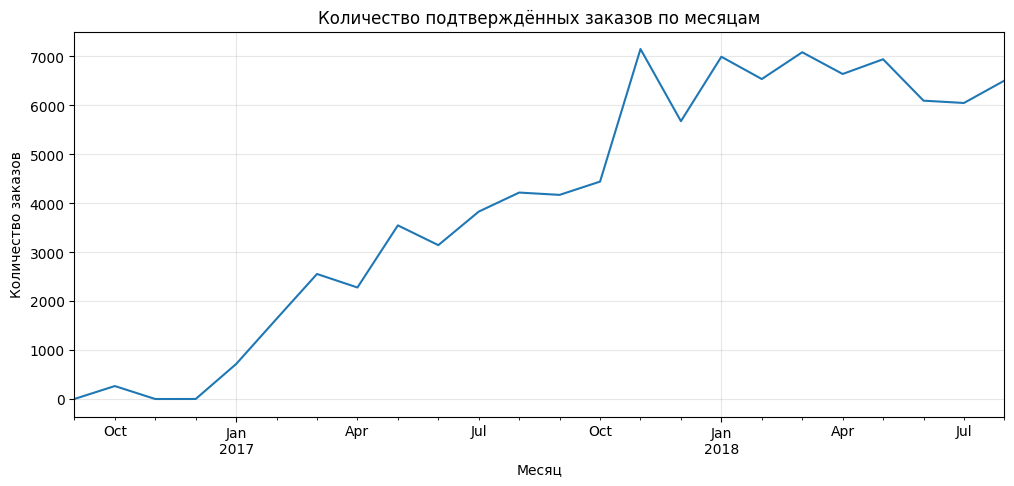

In [17]:
plt.figure(figsize=(12, 5))

orders_by_month.plot()

plt.title("Количество подтверждённых заказов по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Количество заказов")
plt.grid(alpha=0.3)

plt.show()

1. Сначала разберёмся, почему нельзя просто сделать merge

In [18]:
print("orders:")
print("Строк:", len(orders))
print("Уникальных order_id:", orders["order_id"].nunique())

print("\norder_items:")
print("Строк:", len(order_items))
print("Уникальных order_id:", order_items["order_id"].nunique())

orders:
Строк: 99441
Уникальных order_id: 99441

order_items:
Строк: 112650
Уникальных order_id: 98666


In [19]:
# Сколько строк order_items приходится на каждый заказ
items_per_order = (
    order_items
    .groupby("order_id")
    .size()
)

display(items_per_order.describe())

count    98666.000000
mean         1.141731
std          0.538452
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         21.000000
dtype: float64

In [20]:
# Доля заказов с несколькими строками товара
multi_item_share = (items_per_order > 1).mean()

print(
    f"Заказы с несколькими товарными позициями: "
    f"{multi_item_share:.2%}"
)

Заказы с несколькими товарными позициями: 9.94%


In [21]:
order_structure = (
    order_items
    .groupby("order_id")
    .agg(
        items_count=("order_item_id", "count"),
        unique_products=("product_id", "nunique"),
        sellers_count=("seller_id", "nunique"),
    )
    .reset_index()
)

order_structure.head()

,order_id,items_count,unique_products,sellers_count
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,1
1,00018f77f2f0320c557190d7a144bdd3,1,1,1
2,000229ec398224ef6ca0657da4fc703e,1,1,1
3,00024acbcdf0a6daa1e931b038114c75,1,1,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,1


In [22]:
print(
    "Доля заказов с несколькими товарами:",
    (order_structure["items_count"] > 1).mean()
)

print(
    "Доля заказов с несколькими уникальными products:",
    (order_structure["unique_products"] > 1).mean()
)

print(
    "Доля заказов с несколькими sellers:",
    (order_structure["sellers_count"] > 1).mean()
)

Доля заказов с несколькими товарами: 0.09935540105000709
Доля заказов с несколькими уникальными products: 0.032797518902154744
Доля заказов с несколькими sellers: 0.01295279022155555


первые настоящие ML features

In [23]:
# Агрегируем order_items до уровня одного заказа.
# После groupby одна строка должна соответствовать одному order_id.
order_items_features = (
    order_items
    .groupby("order_id")
    .agg(
        # Количество товарных позиций в заказе
        items_count=("order_item_id", "count"),

        # Количество разных товаров
        unique_products=("product_id", "nunique"),

        # Количество продавцов, участвующих в заказе
        sellers_count=("seller_id", "nunique"),

        # Стоимость товаров
        total_price=("price", "sum"),
        avg_item_price=("price", "mean"),
        max_item_price=("price", "max"),
        min_item_price=("price", "min"),

        # Стоимость доставки
        total_freight=("freight_value", "sum"),
        avg_freight=("freight_value", "mean"),
        max_freight=("freight_value", "max"),
    )
    .reset_index()
)

order_items_features.head()

,order_id,items_count,unique_products,sellers_count,total_price,avg_item_price,max_item_price,min_item_price,total_freight,avg_freight,max_freight
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,1,58.90,58.90,58.90,58.90,13.29,13.29,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,1,1,239.90,239.90,239.90,239.90,19.93,19.93,19.93
2,000229ec398224ef6ca0657da4fc703e,1,1,1,199.00,199.00,199.00,199.00,17.87,17.87,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,1,1,12.99,12.99,12.99,12.99,12.79,12.79,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,1,199.90,199.90,199.90,199.90,18.14,18.14,18.14


Добавляем производные признаки

In [24]:
# Цена товаров + стоимость доставки
order_items_features["total_order_value"] = (
    order_items_features["total_price"]
    + order_items_features["total_freight"]
)

In [25]:
# Насколько доставка дорога относительно самого заказа.
#
# replace(0, np.nan) защищает нас от деления на ноль,
# даже если позже появятся заказы с total_price == 0.
order_items_features["freight_to_price_ratio"] = (
    order_items_features["total_freight"]
    / order_items_features["total_price"].replace(0, np.nan)
)

In [26]:
# Есть ли в заказе несколько товарных позиций
order_items_features["is_multi_item"] = (
    order_items_features["items_count"] > 1
).astype("int8")


# Участвуют ли в заказе несколько продавцов
order_items_features["is_multi_seller"] = (
    order_items_features["sellers_count"] > 1
).astype("int8")

In [27]:
order_items_features.head()

,order_id,items_count,unique_products,sellers_count,total_price,avg_item_price,max_item_price,min_item_price,total_freight,avg_freight,max_freight,total_order_value,freight_to_price_ratio,is_multi_item,is_multi_seller
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,1,58.90,58.90,58.90,58.90,13.29,13.29,13.29,72.19,0.225637,0,0
1,00018f77f2f0320c557190d7a144bdd3,1,1,1,239.90,239.90,239.90,239.90,19.93,19.93,19.93,259.83,0.083076,0,0
2,000229ec398224ef6ca0657da4fc703e,1,1,1,199.00,199.00,199.00,199.00,17.87,17.87,17.87,216.87,0.089799,0,0
3,00024acbcdf0a6daa1e931b038114c75,1,1,1,12.99,12.99,12.99,12.99,12.79,12.79,12.79,25.78,0.984604,0,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,1,199.90,199.90,199.90,199.90,18.14,18.14,18.14,218.04,0.090745,0,0


Обязательно проверяем гранулярность

Что такое грануальность?

In [28]:
print("Строк:", len(order_items_features))
print(
    "Уникальных order_id:",
    order_items_features["order_id"].nunique()
)

Строк: 98666
Уникальных order_id: 98666


In [29]:
assert order_items_features["order_id"].is_unique, (
    "После агрегации order_id должен быть уникальным"
)

print("Каждая строка соответствует одному заказу.")

Каждая строка соответствует одному заказу.


Теперь правильно присоединяем признаки к model_df

Что такое model_df?

In [30]:
rows_before_merge = len(model_df)

In [31]:
# Добавляем признаки товаров к основной ML-таблице.
#
# validate="one_to_one" — очень полезная защита:
# pandas проверит, что order_id уникален с обеих сторон.
model_df = model_df.merge(
    order_items_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

In [32]:
rows_after_merge = len(model_df)

print("Строк до merge:", rows_before_merge)
print("Строк после merge:", rows_after_merge)

assert rows_before_merge == rows_after_merge, (
    "После merge изменилось количество заказов"
)

Строк до merge: 96456
Строк после merge: 96456


Проверяем пропуски после merge

In [33]:
item_feature_columns = [
    "items_count",
    "unique_products",
    "sellers_count",
    "total_price",
    "avg_item_price",
    "max_item_price",
    "min_item_price",
    "total_freight",
    "avg_freight",
    "max_freight",
    "total_order_value",
    "freight_to_price_ratio",
    "is_multi_item",
    "is_multi_seller",
]

model_df[item_feature_columns].isna().sum()

items_count               0
unique_products           0
sellers_count             0
total_price               0
avg_item_price            0
max_item_price            0
min_item_price            0
total_freight             0
avg_freight               0
max_freight               0
total_order_value         0
freight_to_price_ratio    0
is_multi_item             0
is_multi_seller           0
dtype: int64

In [34]:
missing_item_features = (
    model_df[item_feature_columns]
    .isna()
    .sum()
    .sum()
)

print(
    "Пропущенных значений в order-item features:",
    missing_item_features
)

Пропущенных значений в order-item features: 0


Посмотрим распределения

In [35]:
model_df[
    [
        "items_count",
        "unique_products",
        "sellers_count",
        "total_price",
        "total_freight",
        "total_order_value",
        "freight_to_price_ratio",
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
items_count,96456.0,1.142220,0.538854,1.00,1.000000,1.000000,1.000000,21.000000
unique_products,96456.0,1.038546,0.227967,1.00,1.000000,1.000000,1.000000,8.000000
sellers_count,96456.0,1.013903,0.123550,1.00,1.000000,1.000000,1.000000,5.000000
total_price,96456.0,137.042574,209.064238,0.85,45.900000,86.500000,149.900000,13440.000000
total_freight,96456.0,22.786159,21.561315,0.00,13.850000,17.170000,24.020000,1794.960000
total_order_value,96456.0,159.828733,218.814239,9.59,61.850000,105.280000,176.270000,13664.080000
freight_to_price_ratio,96456.0,0.308395,0.311637,0.00,0.132017,0.224374,0.380585,21.447059


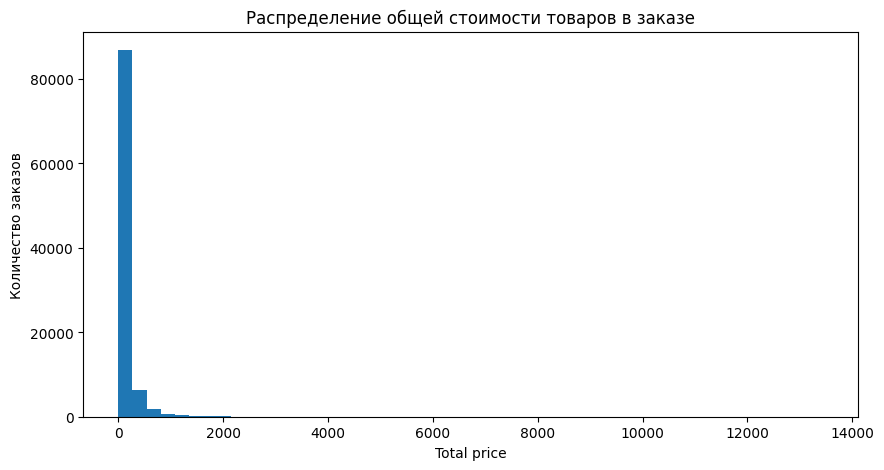

In [36]:
plt.figure(figsize=(10, 5))

plt.hist(
    model_df["total_price"],
    bins=50
)

plt.title("Распределение общей стоимости товаров в заказе")
plt.xlabel("Total price")
plt.ylabel("Количество заказов")

plt.show()

In [37]:
model_df["total_price"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
)

0.50       86.5
0.75      149.9
0.90      269.0
0.95      399.0
0.99      990.0
1.00    13440.0
Name: total_price, dtype: float64

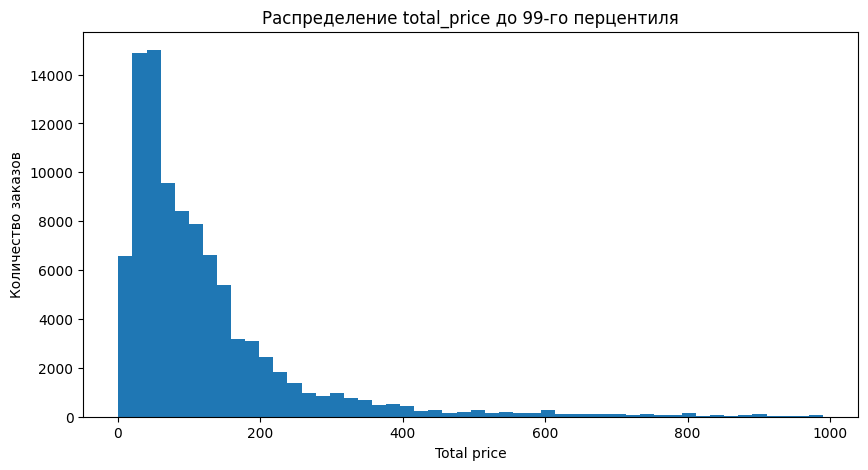

In [38]:
price_99 = model_df["total_price"].quantile(0.99)

plt.figure(figsize=(10, 5))

plt.hist(
    model_df.loc[
        model_df["total_price"] <= price_99,
        "total_price"
    ],
    bins=50
)

plt.title("Распределение total_price до 99-го перцентиля")
plt.xlabel("Total price")
plt.ylabel("Количество заказов")

plt.show()

In [39]:
(
    model_df
    .groupby("late_delivery")
    [
        [
            "items_count",
            "sellers_count",
            "total_price",
            "total_freight",
            "freight_to_price_ratio",
        ]
    ]
    .mean()
    .T
)

late_delivery,0,1
items_count,1.144436,1.111723
sellers_count,1.014768,1.001990
total_price,136.036278,150.891390
total_freight,22.607303,25.247596
freight_to_price_ratio,0.307663,0.318467


In [40]:
def target_rate_by_group(df, column, target="late_delivery"):
    """
    Показывает количество заказов и долю положительного
    класса target для категорий указанного признака.
    """

    result = (
        df
        .groupby(column)[target]
        .agg(
            orders_count="size",
            late_rate="mean"
        )
        .reset_index()
    )

    result["late_rate"] = (
        result["late_rate"] * 100
    ).round(2)

    return result

In [41]:
target_rate_by_group(
    model_df,
    "is_multi_item"
)

,is_multi_item,orders_count,late_rate
0,0,86822,6.94
1,1,9634,5.29


In [42]:
target_rate_by_group(
    model_df,
    "is_multi_seller"
)

,is_multi_seller,orders_count,late_rate
0,0,95181,6.85
1,1,1275,1.02


# Продолжаем ML-проект: от feature engineering к первой модели

До этого момента мы сделали две очень важные вещи:

1. определили **target** `late_delivery`;
2. привели `order_items` к гранулярности **одна строка = один заказ**.

Теперь начинается часть, которая в реальных ML-проектах часто важнее выбора алгоритма: нужно определить, **какие данные модель имеет право видеть в момент предсказания**, собрать дополнительные признаки, корректно разделить данные по времени и построить baseline.

## 1. Сначала фиксируем момент предсказания

Будем считать, что хотим предсказать просрочку **сразу после подтверждения заказа** (`order_approved_at`).

Это решение определяет, какие признаки разрешены.

### Можно использовать

- время покупки и подтверждения;
- обещанную дату доставки;
- состав заказа;
- цену и freight;
- характеристики товаров;
- штат клиента и продавца;
- информацию о способе оплаты.

### Нельзя использовать

- `order_delivered_carrier_date` — это уже событие после подтверждения заказа;
- `order_delivered_customer_date` — по нему построен target;
- review / review score — отзыв появляется после получения заказа;
- признаки, рассчитанные с использованием будущих заказов клиента или продавца.

Это называется **data leakage**. Модель с leakage может показать отличные метрики в ноутбуке и провалиться в реальной работе.

## 2. Временные признаки заказа

Из timestamp обычно не передают модели сам объект `datetime`. Вместо этого извлекают признаки, которые описывают календарный контекст заказа.

Также добавим две бизнес-содержательные величины:

- `approval_delay_hours` — сколько прошло от покупки до подтверждения;
- `promised_delivery_days` — сколько календарных дней магазин обещал на доставку.

Последний признак особенно интересен: длинный обещанный срок может означать сложную логистику, но одновременно даёт продавцу больше запаса времени.

In [43]:
# Сколько часов прошло от оформления заказа до подтверждения оплаты/заказа
model_df["approval_delay_hours"] = (
    model_df["order_approved_at"]
    - model_df["order_purchase_timestamp"]
).dt.total_seconds() / 3600

# Сколько календарных дней было обещано на доставку в момент заказа
model_df["promised_delivery_days"] = (
    model_df["order_estimated_delivery_date"].dt.normalize()
    - model_df["order_purchase_timestamp"].dt.normalize()
).dt.days

# Календарные признаки.
# Мы позже будем рассматривать month/day/hour как категориальные,
# потому что число "12" не должно автоматически считаться в 12 раз
# больше числа "1".
model_df["purchase_month"] = (
    model_df["order_purchase_timestamp"].dt.month
    .astype("Int64")
    .astype("string")
)

model_df["purchase_dayofweek"] = (
    model_df["order_purchase_timestamp"].dt.dayofweek
    .astype("Int64")
    .astype("string")
)

model_df["purchase_hour"] = (
    model_df["order_purchase_timestamp"].dt.hour
    .astype("Int64")
    .astype("string")
)

model_df["is_weekend"] = (
    model_df["order_purchase_timestamp"].dt.dayofweek.isin([5, 6])
).astype("int8")

model_df[
    [
        "approval_delay_hours",
        "promised_delivery_days",
        "purchase_month",
        "purchase_dayofweek",
        "purchase_hour",
        "is_weekend",
    ]
].head()

,approval_delay_hours,promised_delivery_days,purchase_month,purchase_dayofweek,purchase_hour,is_weekend
0,0.178333,16,10,0,10,0
1,30.713889,20,7,1,20,0
2,0.276111,27,8,2,8,0
3,0.298056,27,11,5,19,1
4,1.030556,13,2,1,21,0


## 3. Добавляем данные клиента

В `orders` есть только `customer_id`. Через него можно получить географию клиента.

Для первой модели возьмём `customer_state`. Город и ZIP пока не будем передавать напрямую:

- город создаст много категорий;
- ZIP-код выглядит как число, но математического смысла у расстояния между ZIP `10000` и `20000` нет.

Позже ZIP-коды лучше превратить в настоящие координаты и расстояние между клиентом и продавцом.

In [44]:
customer_features = customers[
    [
        "customer_id",
        "customer_state",
        "customer_zip_code_prefix",
    ]
].copy()

rows_before_merge = len(model_df)

model_df = model_df.merge(
    customer_features,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

assert len(model_df) == rows_before_merge

print("Пропусков в customer_state:", model_df["customer_state"].isna().sum())

Пропусков в customer_state: 0


### Почему здесь `many_to_one`, а не `one_to_one`?

`model_df` содержит заказы, а `customers` — строки клиентов по `customer_id`. Для каждого заказа должен существовать максимум один соответствующий `customer_id` справа.

`validate="many_to_one"` формально разрешает нескольким строкам слева ссылаться на одну строку справа и защищает нас от неожиданного размножения строк при `merge`.

## 4. Характеристики товаров

Таблица `products` находится на уровне **одного товара**, а модель — на уровне **одного заказа**. Поэтому снова нельзя просто сделать merge и оставить результат как есть.

Сначала присоединим характеристики товара к строкам `order_items`, а затем агрегируем их до `order_id`.

Дополнительно посчитаем примерный объём товара в кубических сантиметрах:

`length × height × width`.

In [45]:
product_info = products.copy()

product_info["product_volume_cm3"] = (
    product_info["product_length_cm"]
    * product_info["product_height_cm"]
    * product_info["product_width_cm"]
)

# Теперь каждая строка всё ещё соответствует товарной позиции заказа,
# просто к ней добавились характеристики product_id.
order_product_rows = (
    order_items[
        ["order_id", "product_id", "price"]
    ]
    .merge(
        product_info,
        on="product_id",
        how="left",
        validate="many_to_one"
    )
)

order_product_rows.head()

,order_id,product_id,price,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_volume_cm3
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,58.90,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0,3528.0
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,239.90,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,60000.0
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,199.00,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,14157.0
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,12.99,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0,2400.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,199.90,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0,42000.0


In [46]:
# Числовые характеристики товаров агрегируем до уровня заказа.
product_order_features = (
    order_product_rows
    .groupby("order_id")
    .agg(
        product_categories_count=("product_category_name", "nunique"),

        avg_product_weight_g=("product_weight_g", "mean"),
        max_product_weight_g=("product_weight_g", "max"),

        avg_product_volume_cm3=("product_volume_cm3", "mean"),
        max_product_volume_cm3=("product_volume_cm3", "max"),

        avg_product_photos_qty=("product_photos_qty", "mean"),
        avg_product_name_length=("product_name_lenght", "mean"),
        avg_product_description_length=("product_description_lenght", "mean"),
    )
    .reset_index()
)

# Для категориального признака выберем категорию самого дорогого товара
# в заказе. Это простой способ получить одну "главную" категорию,
# не ломая гранулярность заказа.
main_category = (
    order_product_rows
    .sort_values(
        ["order_id", "price"],
        ascending=[True, False]
    )
    .drop_duplicates("order_id")
    [["order_id", "product_category_name"]]
    .rename(
        columns={"product_category_name": "main_product_category"}
    )
)

product_order_features = product_order_features.merge(
    main_category,
    on="order_id",
    validate="one_to_one"
)

assert product_order_features["order_id"].is_unique

product_order_features.head()

,order_id,product_categories_count,avg_product_weight_g,max_product_weight_g,avg_product_volume_cm3,max_product_volume_cm3,avg_product_photos_qty,avg_product_name_length,avg_product_description_length,main_product_category
0,00010242fe8c5a6d1ba2dd792cb16214,1,650.0,650.0,3528.0,3528.0,4.0,58.0,598.0,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,30000.0,30000.0,60000.0,60000.0,2.0,56.0,239.0,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,3050.0,3050.0,14157.0,14157.0,2.0,59.0,695.0,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,200.0,200.0,2400.0,2400.0,1.0,42.0,480.0,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,3750.0,3750.0,42000.0,42000.0,1.0,59.0,409.0,ferramentas_jardim


In [47]:
rows_before_merge = len(model_df)

model_df = model_df.merge(
    product_order_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

assert len(model_df) == rows_before_merge

print("После product merge строк:", len(model_df))

После product merge строк: 96456


## 5. География продавцов без тяжёлой geolocation-таблицы

До настоящего расстояния в километрах мы дойдём позже. Для первой версии сделаем более простой признак: находится ли продавец в том же штате, что и клиент.

Если в заказе несколько продавцов, считаем долю продавцов из штата клиента.

Обрати внимание: сначала делаем `drop_duplicates([order_id, seller_id])`. Иначе продавец с несколькими товарными позициями получил бы слишком большой вес.

In [48]:
order_sellers = (
    order_items[
        ["order_id", "seller_id"]
    ]
    .drop_duplicates()
    .merge(
        sellers[
            ["seller_id", "seller_state"]
        ],
        on="seller_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        model_df[
            ["order_id", "customer_state"]
        ],
        on="order_id",
        how="inner",
        validate="many_to_one"
    )
)

order_sellers["same_state_seller"] = (
    order_sellers["seller_state"]
    == order_sellers["customer_state"]
).astype("int8")

seller_features = (
    order_sellers
    .groupby("order_id")
    .agg(
        seller_states_count=("seller_state", "nunique"),
        same_state_seller_share=("same_state_seller", "mean"),
    )
    .reset_index()
)

assert seller_features["order_id"].is_unique

rows_before_merge = len(model_df)

model_df = model_df.merge(
    seller_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

assert len(model_df) == rows_before_merge

### 5.1. Географические признаки через `geolocation` и Haversine distance

Признак `same_state_seller_share` полезен, но он очень грубый: два заказа внутри одного штата могут отличаться на сотни километров.

Теперь используем таблицу `olist_geolocation_dataset`:

1. агрегируем координаты до уровня `zip_code_prefix`;
2. присоединяем координаты клиента по `customer_zip_code_prefix`;
3. присоединяем координаты продавца по `seller_zip_code_prefix`;
4. считаем расстояние клиент ↔ продавец по формуле Haversine;
5. агрегируем расстояния до уровня заказа.

Почему снова агрегируем до `order_id`: наша ML-таблица имеет гранулярность **одна строка = один заказ**. Если в заказе несколько продавцов, у заказа будет несколько расстояний, поэтому считаем `mean`, `min`, `max`, `std` и долю продавцов без координат.

In [49]:
# Агрегируем geolocation до уровня ZIP prefix.
# В исходной таблице один и тот же zip prefix встречается много раз,
# поэтому напрямую merge делать нельзя: это размножит строки заказов.
zip_geo = (
    geolocation
    .groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(
        geo_lat=("geolocation_lat", "median"),
        geo_lng=("geolocation_lng", "median"),
    )
    .rename(columns={"geolocation_zip_code_prefix": "zip_code_prefix"})
)

print("Уникальных ZIP prefix с координатами:", zip_geo["zip_code_prefix"].nunique())
print("Строк в zip_geo:", len(zip_geo))

assert zip_geo["zip_code_prefix"].is_unique

Уникальных ZIP prefix с координатами: 19015
Строк в zip_geo: 19015


In [50]:
def haversine_distance_km(lat1, lon1, lat2, lon2):
    """
    Считает расстояние между двумя точками на поверхности Земли.

    На вход можно передавать pandas Series или numpy arrays.
    Результат — расстояние в километрах.
    """

    earth_radius_km = 6371.0

    lat1_rad = np.radians(lat1)
    lon1_rad = np.radians(lon1)
    lat2_rad = np.radians(lat2)
    lon2_rad = np.radians(lon2)

    dlat = lat2_rad - lat1_rad
    dlon = lon2_rad - lon1_rad

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return earth_radius_km * c

In [51]:
# Координаты клиента на уровне заказа.
customer_geo_features = (
    model_df[["order_id", "customer_zip_code_prefix"]]
    .merge(
        zip_geo.rename(
            columns={
                "zip_code_prefix": "customer_zip_code_prefix",
                "geo_lat": "customer_lat",
                "geo_lng": "customer_lng",
            }
        ),
        on="customer_zip_code_prefix",
        how="left",
        validate="many_to_one",
    )
)

# Координаты продавца.
seller_geo_features = (
    sellers[["seller_id", "seller_zip_code_prefix"]]
    .merge(
        zip_geo.rename(
            columns={
                "zip_code_prefix": "seller_zip_code_prefix",
                "geo_lat": "seller_lat",
                "geo_lng": "seller_lng",
            }
        ),
        on="seller_zip_code_prefix",
        how="left",
        validate="many_to_one",
    )
)

# Дистанции считаем на уровне order-seller.
# Если в заказе несколько продавцов, будет несколько строк на один order_id.
order_seller_geo = (
    order_items[["order_id", "seller_id"]]
    .drop_duplicates()
    .merge(
        customer_geo_features,
        on="order_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        seller_geo_features,
        on="seller_id",
        how="left",
        validate="many_to_one",
    )
)

has_both_coordinates = (
    order_seller_geo["customer_lat"].notna()
    & order_seller_geo["customer_lng"].notna()
    & order_seller_geo["seller_lat"].notna()
    & order_seller_geo["seller_lng"].notna()
)

order_seller_geo["seller_customer_distance_km"] = np.nan
order_seller_geo.loc[
    has_both_coordinates,
    "seller_customer_distance_km",
] = haversine_distance_km(
    order_seller_geo.loc[has_both_coordinates, "customer_lat"],
    order_seller_geo.loc[has_both_coordinates, "customer_lng"],
    order_seller_geo.loc[has_both_coordinates, "seller_lat"],
    order_seller_geo.loc[has_both_coordinates, "seller_lng"],
)

# Для редких аномалий координат ограничим расстояния физически возможным диапазоном.
# Максимальное расстояние между двумя точками на Земле примерно 20 000 км.
order_seller_geo.loc[
    order_seller_geo["seller_customer_distance_km"] > 20000,
    "seller_customer_distance_km",
] = np.nan

distance_coverage = float(has_both_coordinates.mean())

print("Order-seller rows:", len(order_seller_geo))
print(
    "Доля order-seller строк с рассчитанной дистанцией:",
    round(distance_coverage, 4),
)

display(order_seller_geo.head())

Order-seller rows: 100010
Доля order-seller строк с рассчитанной дистанцией: 0.973


,order_id,seller_id,customer_zip_code_prefix,customer_lat,customer_lng,seller_zip_code_prefix,seller_lat,seller_lng,seller_customer_distance_km
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,28013.0,-21.762829,-41.310605,27277,-22.498419,-44.125272,301.229205
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,15775.0,-20.205737,-50.926924,3471,-23.564289,-46.519045,588.404069
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,35661.0,-19.870383,-44.594355,37564,-22.271648,-46.165556,312.835023
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,12952.0,-23.104346,-46.595589,14403,-20.554951,-47.387691,295.032480
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,13226.0,-23.245512,-46.825182,87900,-22.930408,-53.136438,646.468544


In [52]:
geo_order_features = (
    order_seller_geo
    .assign(
        seller_geo_missing=(
            order_seller_geo["seller_customer_distance_km"].isna()
        ).astype("int8")
    )
    .groupby("order_id")
    .agg(
        customer_lat=("customer_lat", "first"),
        customer_lng=("customer_lng", "first"),
        seller_customer_distance_km_mean=("seller_customer_distance_km", "mean"),
        seller_customer_distance_km_min=("seller_customer_distance_km", "min"),
        seller_customer_distance_km_max=("seller_customer_distance_km", "max"),
        seller_customer_distance_km_std=("seller_customer_distance_km", "std"),
        seller_geo_missing_share=("seller_geo_missing", "mean"),
    )
    .reset_index()
)

# Если в заказе один продавец, std будет NaN. Для такого случая разброс расстояний равен 0.
geo_order_features["seller_customer_distance_km_std"] = (
    geo_order_features["seller_customer_distance_km_std"].fillna(0)
)

assert geo_order_features["order_id"].is_unique

rows_before_merge = len(model_df)

model_df = model_df.merge(
    geo_order_features,
    on="order_id",
    how="left",
    validate="one_to_one",
)

assert len(model_df) == rows_before_merge

geo_feature_columns = [
    "customer_lat",
    "customer_lng",
    "seller_customer_distance_km_mean",
    "seller_customer_distance_km_min",
    "seller_customer_distance_km_max",
    "seller_customer_distance_km_std",
    "seller_geo_missing_share",
]

print("После geo merge строк:", len(model_df))
display(model_df[geo_feature_columns].describe().T.round(2))

После geo merge строк: 96456


,count,mean,std,min,25%,50%,75%,max
customer_lat,96192.0,-21.20,5.60,-33.69,-23.59,-22.93,-20.14,42.18
customer_lng,96192.0,-46.19,4.06,-72.67,-48.12,-46.63,-43.63,-8.58
seller_customer_distance_km_mean,95980.0,600.71,593.86,0.00,186.87,433.89,797.35,8677.86
seller_customer_distance_km_min,95980.0,599.38,593.96,0.00,182.25,431.95,796.57,8677.86
seller_customer_distance_km_max,95980.0,602.05,594.36,0.00,188.57,435.54,800.19,8677.86
seller_customer_distance_km_std,96456.0,1.85,26.51,0.00,0.00,0.00,0.00,1652.73
seller_geo_missing_share,96456.0,0.00,0.07,0.00,0.00,0.00,0.00,1.00



### 5.2. Leakage-safe historical seller features

На этом шаге добавляем признаки качества продавца, но делаем это осторожно.

Плохой вариант для портфолио:

```python
model_df.merge(order_history.groupby("seller_id").late_delivery.mean())
```

Так делать нельзя: для заказа из 2017 года такая агрегация использовала бы заказы продавца из 2018 года. Это **data leakage**.

Правильная идея: для каждого текущего заказа использовать только те заказы продавца, результат которых уже был известен **до момента предсказания**. В нашем проекте момент предсказания — `order_approved_at`, а результат прошлой доставки становится известен после `order_delivered_customer_date`.

Поэтому для текущего заказа продавца учитываем только историю, где:

```text
past_order_delivered_customer_date < current_order_approved_at
```

Это более строгий вариант, чем просто `past_order_approved_at < current_order_approved_at`, потому что он не использует исход доставки, который на тот момент ещё не был известен бизнесу.


In [53]:

# Собираем таблицу order-seller на уровне одного продавца в одном заказе.
# Один заказ может иметь несколько продавцов, поэтому исторические признаки сначала считаем
# на уровне (order_id, seller_id), а затем агрегируем обратно до order_id.
seller_history_rows = (
    order_items[["order_id", "seller_id"]]
    .drop_duplicates()
    .merge(
        model_df[
            [
                "order_id",
                "order_approved_at",
                "order_estimated_delivery_date",
                "order_delivered_customer_date",
                "late_delivery",
            ]
        ],
        on="order_id",
        how="inner",
        validate="many_to_one",
    )
)

seller_history_rows["prediction_time"] = seller_history_rows["order_approved_at"]
seller_history_rows["outcome_available_at"] = seller_history_rows["order_delivered_customer_date"]

seller_history_rows["delivery_delay_days"] = (
    seller_history_rows["order_delivered_customer_date"].dt.normalize()
    - seller_history_rows["order_estimated_delivery_date"].dt.normalize()
).dt.days

seller_history_rows = seller_history_rows.sort_values(
    ["seller_id", "prediction_time", "order_id"]
).reset_index(drop=True)

print("Order-seller rows:", len(seller_history_rows))
print("Unique sellers:", seller_history_rows["seller_id"].nunique())
display(seller_history_rows.head())


Order-seller rows: 97797
Unique sellers: 2970


,order_id,seller_id,order_approved_at,order_estimated_delivery_date,order_delivered_customer_date,late_delivery,prediction_time,outcome_available_at,delivery_delay_days
0,d455a8cb295653b55abda06d434ab492,0015a82c2db000af6aaaf3ae2ecb0532,2017-09-27 22:24:16,2017-10-30,2017-10-07 16:12:47,0,2017-09-27 22:24:16,2017-10-07 16:12:47,-23
1,9dc8d1a6f16f1b89874c29c9d8d30447,0015a82c2db000af6aaaf3ae2ecb0532,2017-10-12 13:49:22,2017-11-06,2017-10-24 20:17:44,0,2017-10-12 13:49:22,2017-10-24 20:17:44,-13
2,7f39ba4c9052be115350065d07583cac,0015a82c2db000af6aaaf3ae2ecb0532,2017-10-18 23:56:20,2017-11-09,2017-10-27 16:46:05,0,2017-10-18 23:56:20,2017-10-27 16:46:05,-13
3,3c655487f0c8e34cde2c7b67de8f08cc,001cca7ae9ae17fb1caed9dfb1094831,2017-02-04 19:15:39,2017-03-13,2017-03-06 08:28:57,0,2017-02-04 19:15:39,2017-03-06 08:28:57,-7
4,eb188a175542057d90b3ca5628b7b5a0,001cca7ae9ae17fb1caed9dfb1094831,2017-02-19 01:02:43,2017-03-21,2017-02-23 09:23:57,0,2017-02-19 01:02:43,2017-02-23 09:23:57,-26


In [54]:

def build_leakage_safe_seller_history(seller_rows):
    """
    Создаёт исторические признаки продавца без утечки будущего.

    Для каждой строки (order_id, seller_id) берём только те прошлые заказы этого продавца,
    которые уже были доставлены до момента подтверждения текущего заказа.

    Это важно: если прошлый заказ был оформлен раньше текущего, но доставлен позже текущего
    order_approved_at, его outcome ещё неизвестен бизнесу и использовать его нельзя.
    """

    feature_parts = []

    required_columns = [
        "seller_id",
        "order_id",
        "prediction_time",
        "outcome_available_at",
        "late_delivery",
        "delivery_delay_days",
    ]

    missing_columns = sorted(set(required_columns) - set(seller_rows.columns))
    if missing_columns:
        raise ValueError(f"Missing columns: {missing_columns}")

    for seller_id, group in seller_rows.groupby("seller_id", sort=False):
        group = group.copy()

        # История продавца сортируется по моменту, когда результат доставки стал известен.
        history = (
            group
            .dropna(subset=["outcome_available_at"])
            .sort_values("outcome_available_at")
        )

        query_times = group["prediction_time"].to_numpy(dtype="datetime64[ns]")
        history_times = history["outcome_available_at"].to_numpy(dtype="datetime64[ns]")

        known_orders_count = np.searchsorted(
            history_times,
            query_times,
            side="left",
        )

        has_history = known_orders_count > 0

        late_cumsum = history["late_delivery"].astype(float).cumsum().to_numpy()
        delay_cumsum = history["delivery_delay_days"].astype(float).cumsum().to_numpy()
        delay_cummax = history["delivery_delay_days"].astype(float).cummax().to_numpy()

        late_sum = np.zeros(len(group), dtype=float)
        delay_sum = np.zeros(len(group), dtype=float)
        max_delay = np.full(len(group), np.nan, dtype=float)
        days_since_last_delivery = np.full(len(group), np.nan, dtype=float)

        if has_history.any():
            previous_indices = known_orders_count[has_history] - 1

            late_sum[has_history] = late_cumsum[previous_indices]
            delay_sum[has_history] = delay_cumsum[previous_indices]
            max_delay[has_history] = delay_cummax[previous_indices]

            last_known_delivery_times = history_times[previous_indices]
            days_since_last_delivery[has_history] = (
                query_times[has_history] - last_known_delivery_times
            ) / np.timedelta64(1, "D")

        group["seller_known_orders_count"] = known_orders_count.astype("int32")
        group["seller_has_known_history"] = has_history.astype("int8")
        group["seller_known_late_rate"] = np.where(
            has_history,
            late_sum / known_orders_count,
            np.nan,
        )
        group["seller_known_avg_delay_days"] = np.where(
            has_history,
            delay_sum / known_orders_count,
            np.nan,
        )
        group["seller_known_max_delay_days"] = max_delay
        group["seller_days_since_last_known_delivery"] = days_since_last_delivery

        feature_parts.append(
            group[
                [
                    "order_id",
                    "seller_id",
                    "seller_known_orders_count",
                    "seller_has_known_history",
                    "seller_known_late_rate",
                    "seller_known_avg_delay_days",
                    "seller_known_max_delay_days",
                    "seller_days_since_last_known_delivery",
                ]
            ]
        )

    return pd.concat(feature_parts, ignore_index=True)


seller_history_enriched = build_leakage_safe_seller_history(seller_history_rows)

print("Rows with seller history features:", len(seller_history_enriched))
print(
    "Share of order-seller rows with at least one known past delivery:",
    round(seller_history_enriched["seller_has_known_history"].mean(), 4),
)

display(seller_history_enriched.head())


/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:73: RuntimeWarning: invalid value encountered in divide
  late_sum / known_orders_count,
/tmp/ipykernel_2797/2018759788.py:78: RuntimeWarning: invalid value encountered in divide
  delay_sum / known_orders_count,
/tmp/ipykern

Rows with seller history features: 97797
Share of order-seller rows with at least one known past delivery: 0.9469


,order_id,seller_id,seller_known_orders_count,seller_has_known_history,seller_known_late_rate,seller_known_avg_delay_days,seller_known_max_delay_days,seller_days_since_last_known_delivery
0,d455a8cb295653b55abda06d434ab492,0015a82c2db000af6aaaf3ae2ecb0532,0,0,NaN,NaN,NaN,NaN
1,9dc8d1a6f16f1b89874c29c9d8d30447,0015a82c2db000af6aaaf3ae2ecb0532,1,1,0.0,-23.0,-23.0,4.900405
2,7f39ba4c9052be115350065d07583cac,0015a82c2db000af6aaaf3ae2ecb0532,1,1,0.0,-23.0,-23.0,11.321910
3,3c655487f0c8e34cde2c7b67de8f08cc,001cca7ae9ae17fb1caed9dfb1094831,0,0,NaN,NaN,NaN,NaN
4,eb188a175542057d90b3ca5628b7b5a0,001cca7ae9ae17fb1caed9dfb1094831,0,0,NaN,NaN,NaN,NaN


In [55]:

# Агрегируем seller-history признаки обратно до уровня одного заказа.
# Для multi-seller заказов используем mean/max/min: заказ рискованен, если хотя бы один продавец
# имеет плохую историю или продавцы в среднем выглядят ненадёжно.
seller_history_order_features = (
    seller_history_enriched
    .groupby("order_id")
    .agg(
        seller_known_orders_count_mean=("seller_known_orders_count", "mean"),
        seller_known_orders_count_max=("seller_known_orders_count", "max"),
        seller_known_late_rate_mean=("seller_known_late_rate", "mean"),
        seller_known_late_rate_max=("seller_known_late_rate", "max"),
        seller_known_avg_delay_days_mean=("seller_known_avg_delay_days", "mean"),
        seller_known_avg_delay_days_max=("seller_known_avg_delay_days", "max"),
        seller_known_max_delay_days_max=("seller_known_max_delay_days", "max"),
        seller_days_since_last_known_delivery_min=("seller_days_since_last_known_delivery", "min"),
        seller_history_available_share=("seller_has_known_history", "mean"),
    )
    .reset_index()
)

seller_history_order_features["seller_history_missing_share"] = (
    1 - seller_history_order_features["seller_history_available_share"]
)

assert seller_history_order_features["order_id"].is_unique

rows_before_merge = len(model_df)

model_df = model_df.merge(
    seller_history_order_features,
    on="order_id",
    how="left",
    validate="one_to_one",
)

assert len(model_df) == rows_before_merge

historical_seller_feature_columns = [
    "seller_known_orders_count_mean",
    "seller_known_orders_count_max",
    "seller_known_late_rate_mean",
    "seller_known_late_rate_max",
    "seller_known_avg_delay_days_mean",
    "seller_known_avg_delay_days_max",
    "seller_known_max_delay_days_max",
    "seller_days_since_last_known_delivery_min",
    "seller_history_available_share",
    "seller_history_missing_share",
]

print("После seller-history merge строк:", len(model_df))
display(model_df[historical_seller_feature_columns].describe().T.round(4))


После seller-history merge строк: 96456


,count,mean,std,min,25%,50%,75%,max
seller_known_orders_count_mean,96456.0,171.1638,285.0841,0.0,12.0000,52.0000,183.0000,1798.0000
seller_known_orders_count_max,96456.0,172.7040,287.4256,0.0,12.0000,53.0000,185.0000,1798.0000
seller_known_late_rate_mean,91400.0,0.0440,0.0637,0.0,0.0000,0.0309,0.0607,1.0000
seller_known_late_rate_max,91400.0,0.0443,0.0644,0.0,0.0000,0.0311,0.0612,1.0000
seller_known_avg_delay_days_mean,91400.0,-13.5255,5.0103,-140.0,-15.1000,-12.5909,-10.7766,39.0000
seller_known_avg_delay_days_max,91400.0,-13.5015,5.0190,-140.0,-15.0870,-12.5714,-10.7500,39.0000
seller_known_max_delay_days_max,91400.0,17.9414,32.6560,-140.0,-3.0000,10.0000,27.0000,181.0000
seller_days_since_last_known_delivery_min,91400.0,6.2976,16.9024,0.0,0.4367,1.5339,4.9742,563.0265
seller_history_available_share,96456.0,0.9469,0.2234,0.0,1.0000,1.0000,1.0000,1.0000
seller_history_missing_share,96456.0,0.0531,0.2234,0.0,0.0000,0.0000,0.0000,1.0000


## 6. Признаки оплаты

В `order_payments` у одного заказа может быть несколько строк: например, часть оплачена voucher, часть картой.

Поэтому опять агрегируем до `order_id`.

Эти признаки допустимы, потому что наша точка предсказания — после подтверждения заказа. Если бы мы хотели предсказывать просрочку **до оплаты**, использовать их было бы нельзя.

In [56]:
payment_rows = order_payments.copy()

# Превращаем тип оплаты в несколько бинарных индикаторов,
# а затем агрегируем через max: использовался ли этот тип хотя бы раз.
for payment_type in [
    "credit_card",
    "boleto",
    "voucher",
    "debit_card",
]:
    payment_rows[f"uses_{payment_type}"] = (
        payment_rows["payment_type"] == payment_type
    ).astype("int8")

payment_features = (
    payment_rows
    .groupby("order_id")
    .agg(
        payment_transactions=("payment_sequential", "count"),
        payment_types_count=("payment_type", "nunique"),
        payment_value_total=("payment_value", "sum"),
        max_installments=("payment_installments", "max"),

        uses_credit_card=("uses_credit_card", "max"),
        uses_boleto=("uses_boleto", "max"),
        uses_voucher=("uses_voucher", "max"),
        uses_debit_card=("uses_debit_card", "max"),
    )
    .reset_index()
)

assert payment_features["order_id"].is_unique

rows_before_merge = len(model_df)

model_df = model_df.merge(
    payment_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

assert len(model_df) == rows_before_merge

## 7. Проверяем собранную ML-таблицу

На этом этапе `model_df` уже начинает быть похож на настоящую **feature table**: одна строка соответствует объекту, есть target и набор признаков, доступных в выбранный момент предсказания.

Пропуски пока **не будем заполнять вручную во всём DataFrame**. Правильнее делать imputation внутри sklearn `Pipeline`, чтобы статистики заполнения считались только на train и не подсматривали validation/test.

In [57]:
print("Строк:", len(model_df))
print("Уникальных order_id:", model_df["order_id"].nunique())
print("Доля late_delivery:", model_df["late_delivery"].mean().round(4))

assert model_df["order_id"].is_unique

# Посмотрим столбцы с наибольшим количеством пропусков.
missing_after_features = (
    model_df
    .isna()
    .sum()
    .sort_values(ascending=False)
)

display(missing_after_features[missing_after_features > 0].head(15))

Строк: 96456
Уникальных order_id: 96456
Доля late_delivery: 0.0677


seller_known_late_rate_mean                  5056
seller_days_since_last_known_delivery_min    5056
seller_known_max_delay_days_max              5056
seller_known_avg_delay_days_mean             5056
seller_known_avg_delay_days_max              5056
seller_known_late_rate_max                   5056
main_product_category                        1357
avg_product_name_length                      1331
avg_product_description_length               1331
avg_product_photos_qty                       1331
seller_customer_distance_km_max               476
seller_customer_distance_km_mean              476
seller_customer_distance_km_min               476
customer_lng                                  264
customer_lat                                  264
dtype: int64

## 8. Проверяем, меняется ли target со временем

Для временных данных это очень важная проверка. Если распределение target меняется, случайный `train_test_split` смешает прошлое и будущее и может скрыть реальную сложность задачи.

,orders_count,late_rate,late_rate_percent
order_approved_at,,,
2016-09-01,1,1.000000,100.000000
2016-10-01,265,0.007547,0.754717
2016-11-01,0,NaN,NaN
2016-12-01,1,0.000000,0.000000
2017-01-01,715,0.029371,2.937063
2017-02-01,1638,0.028083,2.808303
2017-03-01,2554,0.046202,4.620204
2017-04-01,2278,0.065408,6.540825
2017-05-01,3547,0.030448,3.044827


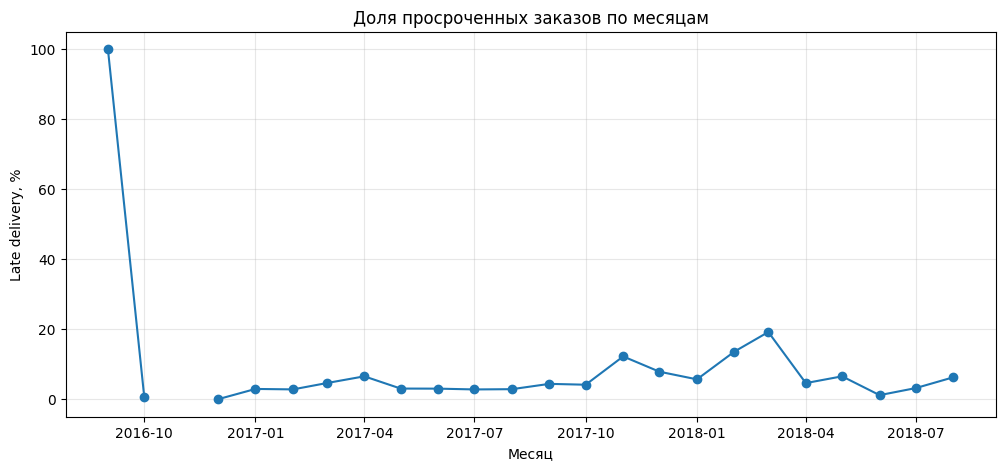

In [58]:
late_rate_by_month = (
    model_df
    .set_index("order_approved_at")
    .resample("MS")["late_delivery"]
    .agg(["size", "mean"])
    .rename(
        columns={
            "size": "orders_count",
            "mean": "late_rate"
        }
    )
)

late_rate_by_month["late_rate_percent"] = (
    late_rate_by_month["late_rate"] * 100
)

display(late_rate_by_month)

plt.figure(figsize=(12, 5))
plt.plot(
    late_rate_by_month.index,
    late_rate_by_month["late_rate_percent"],
    marker="o"
)
plt.title("Доля просроченных заказов по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Late delivery, %")
plt.grid(alpha=0.3)
plt.show()

## 9. Формируем список признаков

Очень полезная привычка — **явно** задавать список признаков, вместо конструкции вроде `X = model_df.drop(...)`.

Так намного сложнее случайно передать модели `order_delivered_customer_date`, `order_status`, `order_id` или другой столбец с leakage.

In [59]:
numerical_features = [
    # order_items
    "items_count",
    "unique_products",
    "sellers_count",
    "total_price",
    "avg_item_price",
    "max_item_price",
    "min_item_price",
    "total_freight",
    "avg_freight",
    "max_freight",
    "total_order_value",
    "freight_to_price_ratio",
    "is_multi_item",
    "is_multi_seller",

    # time
    "approval_delay_hours",
    "promised_delivery_days",
    "is_weekend",

    # products
    "product_categories_count",
    "avg_product_weight_g",
    "max_product_weight_g",
    "avg_product_volume_cm3",
    "max_product_volume_cm3",
    "avg_product_photos_qty",
    "avg_product_name_length",
    "avg_product_description_length",

    # sellers
    "seller_states_count",
    "same_state_seller_share",

    # leakage-safe historical seller features
    "seller_known_orders_count_mean",
    "seller_known_orders_count_max",
    "seller_known_late_rate_mean",
    "seller_known_late_rate_max",
    "seller_known_avg_delay_days_mean",
    "seller_known_avg_delay_days_max",
    "seller_known_max_delay_days_max",
    "seller_days_since_last_known_delivery_min",
    "seller_history_available_share",
    "seller_history_missing_share",

    # geo
    "customer_lat",
    "customer_lng",
    "seller_customer_distance_km_mean",
    "seller_customer_distance_km_min",
    "seller_customer_distance_km_max",
    "seller_customer_distance_km_std",
    "seller_geo_missing_share",

    # payments
    "payment_transactions",
    "payment_types_count",
    "payment_value_total",
    "max_installments",
    "uses_credit_card",
    "uses_boleto",
    "uses_voucher",
    "uses_debit_card",
]

categorical_features = [
    "customer_state",
    "main_product_category",
    "purchase_month",
    "purchase_dayofweek",
    "purchase_hour",
]

feature_columns = numerical_features + categorical_features
target_column = "late_delivery"

print("Числовых признаков:", len(numerical_features))
print("Категориальных признаков:", len(categorical_features))
print("Всего признаков до One-Hot Encoding:", len(feature_columns))

Числовых признаков: 52
Категориальных признаков: 5
Всего признаков до One-Hot Encoding: 57


## 10. Хронологический train / validation / test split

Для обычного учебного датасета часто используют случайный split. Для заказов во времени реалистичнее другой сценарий:

- **train** — старые заказы, на них учимся;
- **validation** — более новые, на них принимаем решения о модели и threshold;
- **test** — самые новые, к ним не прикасаемся до финальной проверки.

Возьмём примерно 70% / 15% / 15% по времени.

In [60]:
train_cutoff = model_df["order_approved_at"].quantile(0.70)
valid_cutoff = model_df["order_approved_at"].quantile(0.85)

train_df = model_df.loc[
    model_df["order_approved_at"] <= train_cutoff
].copy()

valid_df = model_df.loc[
    (model_df["order_approved_at"] > train_cutoff)
    & (model_df["order_approved_at"] <= valid_cutoff)
].copy()

test_df = model_df.loc[
    model_df["order_approved_at"] > valid_cutoff
].copy()

split_summary = pd.DataFrame({
    "rows": [
        len(train_df),
        len(valid_df),
        len(test_df),
    ],
    "late_rate_percent": [
        train_df[target_column].mean() * 100,
        valid_df[target_column].mean() * 100,
        test_df[target_column].mean() * 100,
    ],
    "date_from": [
        train_df["order_approved_at"].min(),
        valid_df["order_approved_at"].min(),
        test_df["order_approved_at"].min(),
    ],
    "date_to": [
        train_df["order_approved_at"].max(),
        valid_df["order_approved_at"].max(),
        test_df["order_approved_at"].max(),
    ],
}, index=["train", "validation", "test"])

split_summary["late_rate_percent"] = (
    split_summary["late_rate_percent"].round(2)
)

display(split_summary)

,rows,late_rate_percent,date_from,date_to
train,67519,7.83,2016-09-15 12:16:38,2018-04-16 09:15:20
validation,14468,4.34,2018-04-16 09:31:24,2018-06-21 12:40:50
test,14469,4.28,2018-06-21 12:41:03,2018-08-29 15:10:26


In [61]:
X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_valid = valid_df[feature_columns]
y_valid = valid_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

print(X_train.shape, X_valid.shape, X_test.shape)

(67519, 57) (14468, 57) (14469, 57)


## 11. Preprocessing через `Pipeline`

У нас есть два разных типа признаков.

### Числовые

1. пропуски → медиана, рассчитанная **только на train**;
2. `StandardScaler` → нужен Logistic Regression, потому что признаки имеют очень разные масштабы.

### Категориальные

1. пропуски → самая частая категория train;
2. `OneHotEncoder` → превращает категории в бинарные столбцы.

`handle_unknown="ignore"` особенно важен для временного split: в validation/test может появиться категория, которой ещё не было в train.

In [62]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
    precision_recall_curve,
)

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

## 12. Функция оценки модели

Target несбалансирован: просрочек мало. Поэтому обычная `accuracy` почти бесполезна.

Модель, которая всегда говорит «доставка будет вовремя», получит очень высокую accuracy — и не найдёт ни одной просрочки.

Поэтому смотрим:

- **ROC-AUC** — насколько хорошо модель ранжирует классы;
- **Average Precision (PR-AUC)** — особенно полезна при редком положительном классе;
- **precision** — какая доля наших предупреждений действительно была просрочкой;
- **recall** — какую долю всех просрочек мы нашли;
- **F1** — компромисс precision/recall;
- **balanced accuracy** — средняя полнота двух классов.

In [63]:
def evaluate_classifier(
    model,
    X,
    y_true,
    threshold=0.5,
    title="Model"
):
    """
    Оценивает бинарный классификатор по вероятностям.

    threshold отделён от самой модели специально:
    в бизнес-задаче граница 0.5 далеко не всегда оптимальна.
    """

    y_proba = model.predict_proba(X)[:, 1]
    y_pred = (y_proba >= threshold).astype("int8")

    metrics = pd.Series({
        "roc_auc": roc_auc_score(y_true, y_proba),
        "average_precision": average_precision_score(y_true, y_proba),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "predicted_positive_rate": y_pred.mean(),
    }, name=title)

    display(metrics.to_frame().T.round(4))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        values_format="d"
    )
    plt.title(
        f"{title}: confusion matrix, threshold={threshold:.3f}"
    )
    plt.show()

    return metrics, y_proba, y_pred

## 13. Dummy baseline

Перед «настоящей» моделью нужен максимально простой baseline.

`DummyClassifier(strategy="prior")` вообще не изучает зависимости между признаками и target. Он только запоминает долю классов в train.

Если сложная модель не превосходит такой baseline, значит либо признаки слабые, либо pipeline содержит проблему.

,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
Dummy validation,0.5,0.0434,0.0,0.0,0.0,0.5,0.0


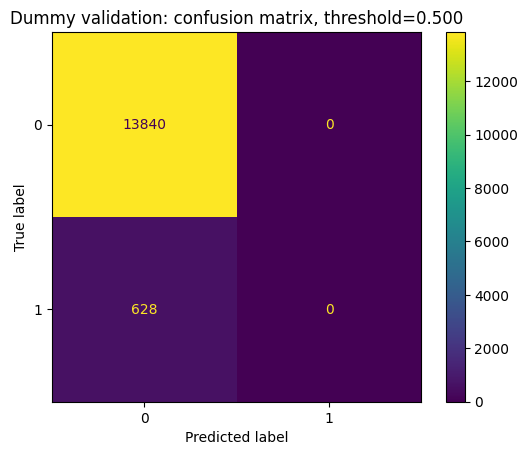

In [64]:
dummy_model = DummyClassifier(strategy="prior")
dummy_model.fit(X_train, y_train)

dummy_valid_metrics, dummy_valid_proba, dummy_valid_pred = evaluate_classifier(
    dummy_model,
    X_valid,
    y_valid,
    threshold=0.5,
    title="Dummy validation"
)

## 14. Первая настоящая модель — Logistic Regression

Начинать с Logistic Regression полезно даже если потом мы перейдём к CatBoost / LightGBM / XGBoost.

Почему:

- быстро обучается;
- создаёт сильный и понятный baseline;
- хорошо работает с One-Hot категориальными признаками;
- её результат легче отлаживать;
- если даже линейная модель получает сигнал, значит feature engineering уже несёт полезную информацию.

Используем `class_weight="balanced"`, потому что положительный класс редкий. Это не «исправляет» дисбаланс магически, но увеличивает штраф за ошибки на редком классе.

In [65]:
logreg_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced"
            )
        ),
    ]
)

logreg_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers c

,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
Logistic Regression validation,0.7413,0.1117,0.1235,0.4156,0.1904,0.6409,0.146


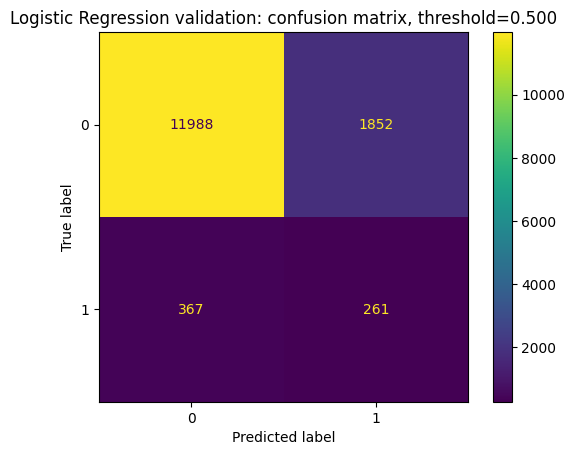

In [66]:
logreg_valid_metrics, valid_proba, valid_pred = evaluate_classifier(
    logreg_model,
    X_valid,
    y_valid,
    threshold=0.5,
    title="Logistic Regression validation"
)

## 15. Почему threshold = 0.5 — не закон

Классификатор сначала выдаёт вероятность. Решение `0/1` появляется только после выбора threshold.

Например:

- низкий threshold → найдём больше просрочек (**recall ↑**), но будет больше ложных тревог (**precision ↓**);
- высокий threshold → тревог будет меньше и они станут точнее, но часть просрочек мы пропустим.

В реальном проекте threshold выбирают из стоимости двух ошибок. Пока такой бизнес-функции у нас нет, поэтому для учебного baseline найдём threshold с максимальным F1 **только на validation**.

In [67]:
precision_values, recall_values, thresholds = precision_recall_curve(
    y_valid,
    valid_proba
)

# У precision/recall на один элемент больше, чем thresholds.
# Поэтому последний элемент не участвует в расчёте F1 для threshold.
f1_values = (
    2
    * precision_values[:-1]
    * recall_values[:-1]
    / (
        precision_values[:-1]
        + recall_values[:-1]
        + 1e-12
    )
)

best_index = np.nanargmax(f1_values)
best_threshold = thresholds[best_index]

print(f"Best validation threshold: {best_threshold:.3f}")
print(f"Validation precision: {precision_values[best_index]:.3f}")
print(f"Validation recall: {recall_values[best_index]:.3f}")
print(f"Validation F1: {f1_values[best_index]:.3f}")

Best validation threshold: 0.550
Validation precision: 0.144
Validation recall: 0.355
Validation F1: 0.204


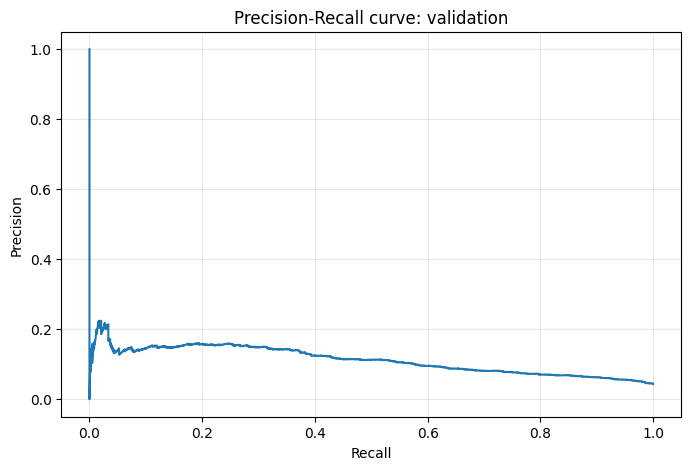

In [68]:
plt.figure(figsize=(8, 5))
plt.plot(recall_values, precision_values)
plt.title("Precision-Recall curve: validation")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid(alpha=0.3)
plt.show()

## 16. Финальная проверка на test

До этого момента test не использовался ни для обучения, ни для выбора threshold.

Теперь применяем **ровно тот threshold, который выбрали на validation**, и один раз измеряем качество на самых новых заказах.

Если после этого начать менять признаки или threshold, ориентируясь на test, test фактически превратится ещё в один validation set.

,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
Logistic Regression test,0.6634,0.0738,0.0859,0.1874,0.1178,0.5491,0.0934


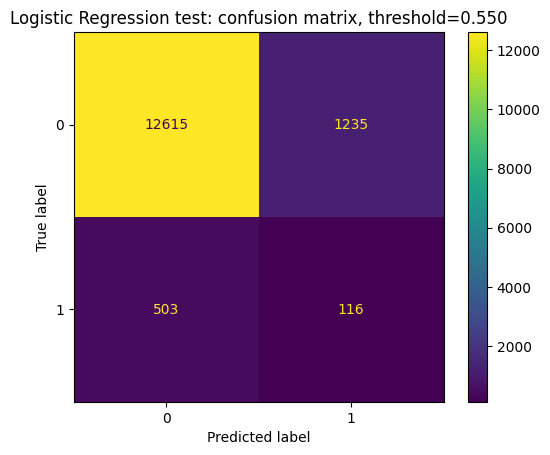

In [69]:
logreg_test_metrics, test_proba, test_pred = evaluate_classifier(
    logreg_model,
    X_test,
    y_test,
    threshold=best_threshold,
    title="Logistic Regression test"
)

## 17. Смотрим коэффициенты Logistic Regression

Это не полноценная causal-интерпретация, но очень полезный sanity check.

После preprocessing мы можем получить реальные имена One-Hot признаков и посмотреть, какие коэффициенты модель сделала наиболее положительными и отрицательными.

Важно: коэффициент показывает связь **при фиксированных остальных признаках**, а не доказывает, что признак является причиной просрочки.

In [70]:
feature_names_after_preprocessing = (
    logreg_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

coefficients = (
    logreg_model
    .named_steps["model"]
    .coef_[0]
)

coefficient_table = (
    pd.DataFrame({
        "feature": feature_names_after_preprocessing,
        "coefficient": coefficients,
    })
    .sort_values("coefficient", ascending=False)
)

print("Признаки, сильнее связанные с late_delivery = 1")
display(coefficient_table.head(15))

print("Признаки, сильнее связанные с late_delivery = 0")
display(coefficient_table.tail(15).sort_values("coefficient"))

Признаки, сильнее связанные с late_delivery = 1


,feature,coefficient
73,cat__customer_state_RR,1.799185
53,cat__customer_state_AL,1.559917
29,num__seller_known_late_rate_mean,1.178127
156,cat__purchase_month_3,1.040821
106,cat__main_product_category_dvds_blu_ray,0.943547
155,cat__purchase_month_2,0.936306
61,cat__customer_state_MA,0.878773
65,cat__customer_state_PA,0.876894
137,cat__main_product_category_musica,0.782554
28,num__seller_known_orders_count_max,0.745469


Признаки, сильнее связанные с late_delivery = 0


,feature,coefficient
69,cat__customer_state_PR,-1.447606
82,cat__main_product_category_artes,-1.300006
79,cat__main_product_category_agro_industria_e_co...,-1.258301
30,num__seller_known_late_rate_max,-1.154822
77,cat__customer_state_SP,-1.145853
62,cat__customer_state_MG,-1.121498
74,cat__customer_state_RS,-1.021111
84,cat__main_product_category_artigos_de_festas,-0.907200
58,cat__customer_state_DF,-0.870278
160,cat__purchase_month_7,-0.777802


# Что мы построили на этом этапе

Теперь ноутбук уже содержит минимальный, но правильный **end-to-end ML pipeline**:

1. определена бизнес-задача и target;
2. зафиксирован prediction moment;
3. проверена гранулярность данных;
4. сделан feature engineering из нескольких таблиц;
5. явно исключены признаки с leakage;
6. данные разделены хронологически;
7. preprocessing находится внутри `Pipeline`;
8. есть Dummy baseline;
9. обучена Logistic Regression;
10. метрики учитывают дисбаланс классов;
11. threshold выбирается на validation;
12. test остаётся честной финальной проверкой.

Следующий логичный этап проекта — **не добавлять десять моделей сразу**. Сначала нужно провести error analysis: понять, на каких заказах Logistic Regression ошибается, затем добавить географическое расстояние через `geolocation`, исторические признаки продавцов без leakage и только после этого сравнить линейную модель с деревьями/boosting.

## 18. Random Forest benchmark

Теперь добавляем вторую модель — `RandomForestClassifier`.

Важно: это ещё не финальная production-модель. Это **сильный нелинейный benchmark**, который помогает понять, есть ли в данных зависимости, которые Logistic Regression не ловит.

Почему Random Forest полезен на этом этапе:

- умеет находить нелинейные зависимости;
- умеет работать с взаимодействиями признаков;
- не требует масштабирования числовых признаков;
- даёт базовую оценку важности признаков;
- хорошо подходит как промежуточная модель перед CatBoost.

При этом мы не используем `test`: все решения пока принимаются только по validation.

### 18.1. Отдельный preprocessing для tree-based моделей

Для Logistic Regression мы масштабировали числовые признаки через `StandardScaler`, потому что линейные модели чувствительны к масштабу.

Для Random Forest масштабирование обычно не нужно: деревья делают разбиения вида `feature <= threshold`, и линейный масштаб признака им почти не важен.

Поэтому создадим отдельный preprocessing:

- числовые признаки: только `SimpleImputer(strategy="median")`;
- категориальные признаки: `SimpleImputer` + `OneHotEncoder`.

Мы не переиспользуем уже обученный `preprocessor`, чтобы модели были независимыми друг от друга.

In [71]:
tree_numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

tree_categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        ),
    ]
)

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", tree_numeric_pipeline, numerical_features),
        ("cat", tree_categorical_pipeline, categorical_features),
    ]
)

### 18.2. Обучаем Random Forest

Параметры здесь выбраны как **разумный первый benchmark**, а не как результат тюнинга.

Что означают основные настройки:

- `n_estimators=15` — строим 60 деревьев;
- `max_depth=8` — ограничиваем глубину, чтобы модель не слишком переобучалась;
- `min_samples_leaf=20` — в листе должно быть минимум 100 объектов, это сглаживает слишком специфичные правила;
- `class_weight="balanced_subsample"` — учитываем дисбаланс классов внутри bootstrap-выборок;
- `max_samples=0.50` — каждое дерево обучается на половине train, чтобы benchmark запускался быстрее;
- `n_jobs=2` — используем 2 ядра CPU, чтобы ноутбук не перегружал окружение.

Позже, когда базовый benchmark будет стабилен, эти параметры можно будет подбирать через `RandomizedSearchCV` или Optuna.

In [72]:
rf_model = Pipeline(
    steps=[
        ("preprocessing", tree_preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=15,
                max_depth=8,
                min_samples_leaf=100,
                max_features="sqrt",
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=2,
                max_samples=0.50,
            )
        ),
    ]
)

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers c

### 18.3. Оцениваем Random Forest на validation

Сначала смотрим качество при стандартном threshold `0.5`.

Но для несбалансированной задачи это не финальное решение: ROC-AUC и Average Precision оценивают качество ранжирования, а Precision / Recall / F1 зависят от выбранного порога.

,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
"Random Forest validation, threshold=0.5",0.6323,0.0668,0.069,0.4666,0.1203,0.5905,0.2933


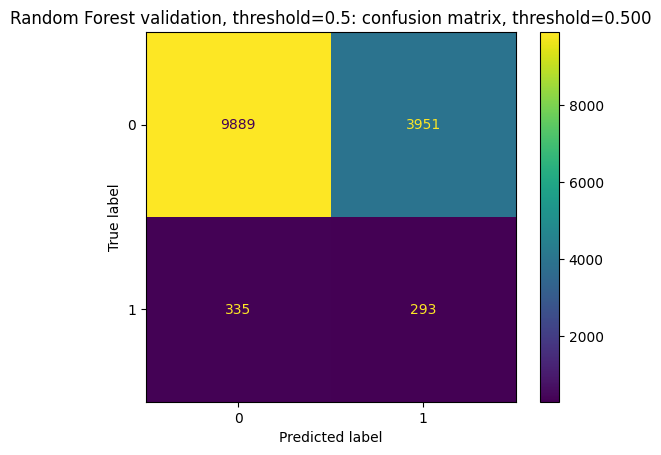

In [73]:
rf_valid_metrics_05, rf_valid_proba, rf_valid_pred_05 = evaluate_classifier(
    rf_model,
    X_valid,
    y_valid,
    threshold=0.5,
    title="Random Forest validation, threshold=0.5"
)

### 18.4. Подбор threshold для Random Forest

Здесь мы подбираем threshold **только на validation**.

Это важное правило:

- train используется для обучения;
- validation используется для выбора модели и threshold;
- test остаётся закрытым до финального сравнения.

Сейчас оптимизируем F1 как компромисс между precision и recall.

In [74]:
def find_best_f1_threshold(y_true, y_proba):
    """
    Находит threshold, который максимизирует F1 на validation.

    Функция не обучает модель и не трогает test.
    Она только выбирает границу принятия решения по уже рассчитанным вероятностям.
    """

    precision_values, recall_values, thresholds = precision_recall_curve(
        y_true,
        y_proba
    )

    f1_values = (
        2
        * precision_values[:-1]
        * recall_values[:-1]
        / (
            precision_values[:-1]
            + recall_values[:-1]
            + 1e-12
        )
    )

    best_index = np.nanargmax(f1_values)

    threshold_report = pd.Series({
        "best_threshold": thresholds[best_index],
        "precision": precision_values[best_index],
        "recall": recall_values[best_index],
        "f1": f1_values[best_index],
    })

    return thresholds[best_index], threshold_report


rf_best_threshold, rf_threshold_report = find_best_f1_threshold(
    y_valid,
    rf_valid_proba
)

display(rf_threshold_report.to_frame("Random Forest best F1 threshold").T.round(4))

,best_threshold,precision,recall,f1
Random Forest best F1 threshold,0.5084,0.0716,0.4443,0.1234


,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
"Random Forest validation, best F1 threshold",0.6323,0.0668,0.0716,0.4443,0.1234,0.5915,0.2691


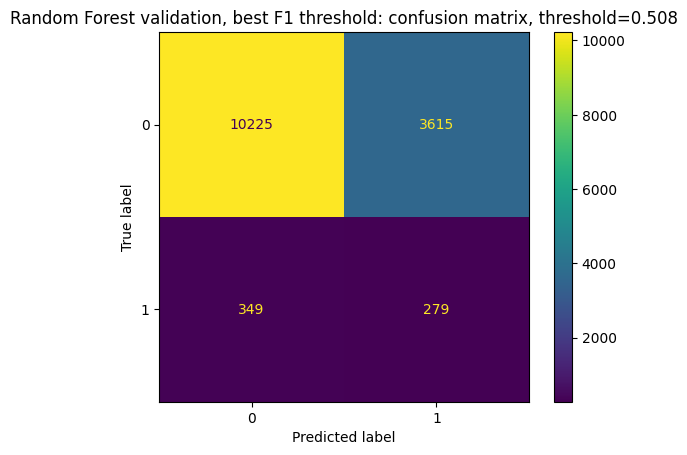

In [75]:
rf_valid_metrics_best, rf_valid_proba_best, rf_valid_pred_best = evaluate_classifier(
    rf_model,
    X_valid,
    y_valid,
    threshold=rf_best_threshold,
    title="Random Forest validation, best F1 threshold"
)

## 19. Сравнение baseline, Logistic Regression и Random Forest

Теперь можно собрать первые результаты в одну таблицу.

На этом этапе главное смотреть не только на F1:

- `roc_auc` показывает, насколько хорошо модель ранжирует заказы от менее рискованных к более рискованным;
- `average_precision` особенно полезна при дисбалансе классов;
- `recall` показывает, какую долю реально просроченных заказов модель нашла;
- `precision` показывает, какая доля предупреждений действительно оказалась просрочкой;
- `predicted_positive_rate` показывает, какой процент заказов модель помечает как рискованные.

Для бизнес-задачи доставки это важно: слишком высокий recall при очень низком precision может означать, что операционная команда будет перегружена ложными тревогами.

In [76]:
model_results = pd.DataFrame([
    dummy_valid_metrics.rename("Dummy baseline"),
    logreg_valid_metrics.rename("Logistic Regression, threshold=0.5"),
    rf_valid_metrics_05.rename("Random Forest, threshold=0.5"),
    rf_valid_metrics_best.rename("Random Forest, best F1 threshold"),
])

model_results = model_results[
    [
        "roc_auc",
        "average_precision",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "predicted_positive_rate",
    ]
]

model_results_sorted = model_results.sort_values(
    by="average_precision",
    ascending=False
)

display(model_results_sorted.round(4))

,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
"Logistic Regression, threshold=0.5",0.7413,0.1117,0.1235,0.4156,0.1904,0.6409,0.1460
"Random Forest, threshold=0.5",0.6323,0.0668,0.0690,0.4666,0.1203,0.5905,0.2933
"Random Forest, best F1 threshold",0.6323,0.0668,0.0716,0.4443,0.1234,0.5915,0.2691
Dummy baseline,0.5000,0.0434,0.0000,0.0000,0.0000,0.5000,0.0000


## 20. Feature importance Random Forest

Random Forest позволяет получить встроенную важность признаков через `feature_importances_`.

Это не идеальная интерпретация:

- важности могут быть смещены в сторону признаков с большим количеством возможных разбиений;
- после One-Hot Encoding один исходный категориальный признак распадается на много отдельных колонок;
- это не causal interpretation.

Но как быстрый sanity check это полезно: мы смотрим, не опирается ли модель на странные признаки и какие группы признаков дают основной сигнал.

Top-25 признаков Random Forest:


,feature,importance
77,cat__customer_state_SP,0.094909
156,cat__purchase_month_3,0.079818
32,num__seller_known_avg_delay_days_max,0.070764
31,num__seller_known_avg_delay_days_mean,0.066432
38,num__customer_lng,0.061137
37,num__customer_lat,0.045982
39,num__seller_customer_distance_km_mean,0.040794
8,num__avg_freight,0.040225
41,num__seller_customer_distance_km_max,0.036182
15,num__promised_delivery_days,0.030716


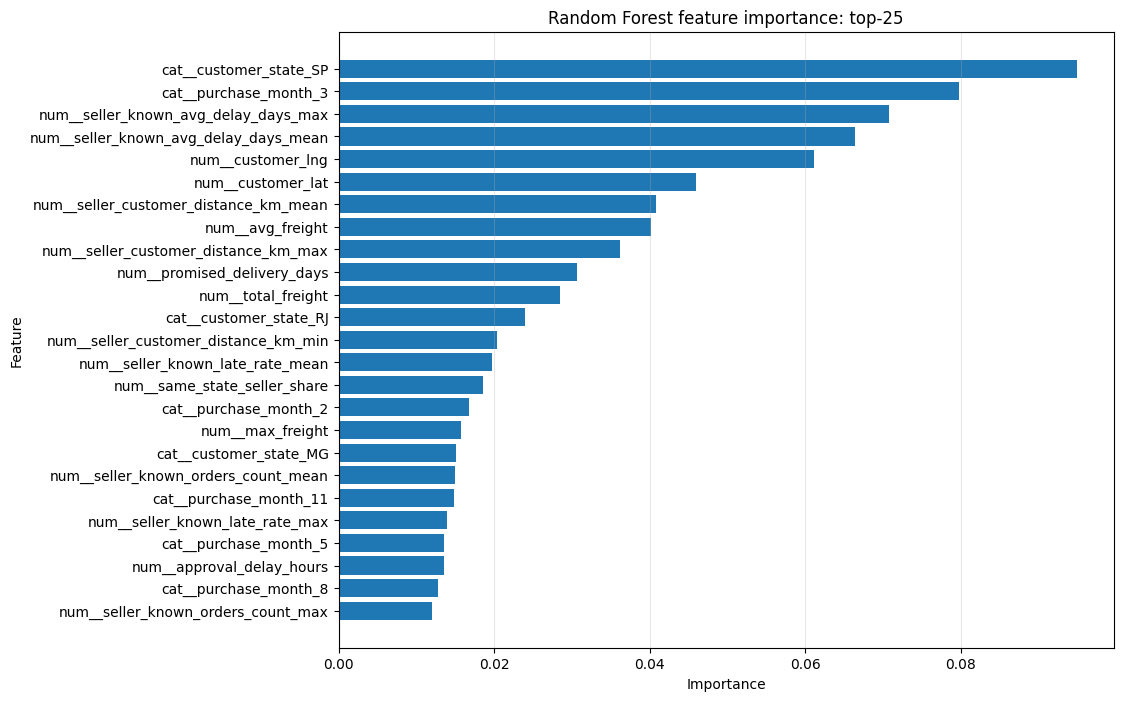

In [77]:
rf_feature_names = (
    rf_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

rf_importances = (
    rf_model
    .named_steps["model"]
    .feature_importances_
)

rf_importance_table = (
    pd.DataFrame({
        "feature": rf_feature_names,
        "importance": rf_importances,
    })
    .sort_values("importance", ascending=False)
)

print("Top-25 признаков Random Forest:")
display(rf_importance_table.head(25))

plt.figure(figsize=(10, 8))
plt.barh(
    rf_importance_table.head(25)["feature"][::-1],
    rf_importance_table.head(25)["importance"][::-1],
)
plt.title("Random Forest feature importance: top-25")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.show()

## Checkpoint после Random Forest

На этом шаге мы добавили первый серьёзный нелинейный benchmark и получили таблицу сравнения моделей на validation.

Что уже должно быть в рабочем состоянии:

1. загрузка данных через `kagglehub`;
2. сбор `model_df` на уровне одного заказа;
3. временной split train / validation / test;
4. Dummy baseline;
5. Logistic Regression;
6. Random Forest;
7. сравнение моделей на validation;
8. feature importance для Random Forest.

Следующий логичный шаг — добавить **CatBoost** как основную модель для табличных данных с категориальными признаками. Но это стоит делать только после проверки, что текущий ноутбук выполняется без ошибок.

## 21. CatBoost benchmark

Теперь добавляем **CatBoost** как основную модель-кандидат для табличных данных.

Почему CatBoost здесь уместен:

- в данных есть категориальные признаки: штат клиента, категория товара, месяц, день недели, час покупки;
- CatBoost умеет работать с категориальными признаками напрямую, без ручного One-Hot Encoding;
- градиентный бустинг обычно сильнее Random Forest на табличных задачах;
- модель поддерживает `early_stopping`, поэтому мы можем остановить обучение, когда качество на validation перестаёт улучшаться.

Важно: мы по-прежнему не используем `test` для выбора модели, параметров или threshold. Все решения принимаются только на validation.

### 21.1. Импорт CatBoost

В разных окружениях CatBoost может быть не установлен по умолчанию. Поэтому импорт вынесен в отдельную ячейку: если пакет отсутствует, ноутбук явно покажет, что нужно установить.

В портфолио-проекте лучше не скрывать зависимости: дополнительно можно вынести их в `requirements.txt`.

In [ ]:

# Environment setup for optional ML libraries.
# In Colab/Kaggle these packages are often preinstalled,
# but for a clean local environment we install missing dependencies.

import importlib.util
import subprocess
import sys

required_packages = {
    "catboost": "catboost",
    "shap": "shap",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        subprocess.check_call(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                package_name,
                "-q",
            ]
        )

print("Optional ML dependencies are ready.")


In [78]:
try:
    from catboost import CatBoostClassifier, Pool
except ImportError as error:
    raise ImportError(
        "CatBoost is not installed. Install it with: pip install catboost"
    ) from error

### 21.2. Подготовка данных для CatBoost

Для Logistic Regression и Random Forest мы использовали sklearn preprocessing.

Для CatBoost сделаем отдельную подготовку:

- числовые признаки оставляем числовыми;
- категориальные признаки приводим к `str`;
- пропуски в категориальных признаках заменяем на строку `"missing"`;
- пропуски в числовых признаках оставляем как `NaN`, потому что CatBoost умеет с ними работать.

Почему не используем One-Hot Encoding: CatBoost умеет кодировать категории внутри алгоритма и часто делает это лучше, чем ручной One-Hot для бустинга.

In [79]:
def prepare_catboost_data(X, numerical_features, categorical_features):
    """
    Готовит признаки для CatBoost.

    CatBoost требует, чтобы категориальные признаки были строками или целыми значениями
    без NaN. Поэтому категориальные колонки явно приводим к string и заполняем пропуски.

    Числовые признаки оставляем числовыми. NaN в числовых колонках CatBoost умеет
    обрабатывать самостоятельно.
    """

    X_prepared = X.copy()

    for column in numerical_features:
        X_prepared[column] = pd.to_numeric(
            X_prepared[column],
            errors="coerce"
        )

    for column in categorical_features:
        X_prepared[column] = (
            X_prepared[column]
            .astype("object")
            .where(X_prepared[column].notna(), "missing")
            .astype(str)
        )

    return X_prepared


X_train_cb = prepare_catboost_data(
    X_train,
    numerical_features=numerical_features,
    categorical_features=categorical_features,
)

X_valid_cb = prepare_catboost_data(
    X_valid,
    numerical_features=numerical_features,
    categorical_features=categorical_features,
)

X_test_cb = prepare_catboost_data(
    X_test,
    numerical_features=numerical_features,
    categorical_features=categorical_features,
)

cat_feature_indices = [
    X_train_cb.columns.get_loc(column)
    for column in categorical_features
]

print("CatBoost categorical features:")
for column, index in zip(categorical_features, cat_feature_indices):
    print(f"{index}: {column}")

print("\nTrain shape:", X_train_cb.shape)
print("Validation shape:", X_valid_cb.shape)
print("Test shape:", X_test_cb.shape)

CatBoost categorical features:
52: customer_state
53: main_product_category
54: purchase_month
55: purchase_dayofweek
56: purchase_hour

Train shape: (67519, 57)
Validation shape: (14468, 57)
Test shape: (14469, 57)


### 21.3. Создаём `Pool`

`Pool` — это внутренний формат данных CatBoost.

Он полезен потому, что мы один раз явно передаём:

- матрицу признаков;
- target;
- индексы категориальных признаков.

Так меньше риска забыть `cat_features` при обучении или оценке.

In [80]:
train_pool = Pool(
    data=X_train_cb,
    label=y_train,
    cat_features=cat_feature_indices,
)

valid_pool = Pool(
    data=X_valid_cb,
    label=y_valid,
    cat_features=cat_feature_indices,
)

test_pool = Pool(
    data=X_test_cb,
    label=y_test,
    cat_features=cat_feature_indices,
)

### 21.4. Обучаем CatBoost

Параметры здесь — не финальный тюнинг, а воспроизводимый первый benchmark.

Ключевые настройки:

- `loss_function="Logloss"` — стандартная функция потерь для бинарной классификации;
- `eval_metric="AUC"` — CatBoost будет отслеживать ROC-AUC на validation;
- `auto_class_weights="Balanced"` — учитываем дисбаланс классов;
- `early_stopping_rounds=50` — останавливаем обучение, если validation AUC долго не улучшается;
- `use_best_model=True` — в финальной модели сохраняется лучшая итерация по validation.

`test` здесь не используется.

In [81]:
catboost_model = CatBoostClassifier(
    iterations=150,
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=6,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=42,
    early_stopping_rounds=40,
    verbose=50,
    allow_writing_files=False,
    thread_count=4,
)

catboost_model.fit(
    train_pool,
    eval_set=valid_pool,
    use_best_model=True,
)

print("Best iteration:", catboost_model.get_best_iteration())
print("Best validation scores:", catboost_model.get_best_score())

0:	test: 0.5998306	best: 0.5998306 (0)	total: 74.1ms	remaining: 11s


50:	test: 0.6862767	best: 0.6862767 (50)	total: 1.19s	remaining: 2.31s


100:	test: 0.7089087	best: 0.7089469 (99)	total: 2.35s	remaining: 1.14s


149:	test: 0.7222283	best: 0.7222283 (149)	total: 3.56s	remaining: 0us

bestTest = 0.7222283329
bestIteration = 149

Best iteration: 149
Best validation scores: {'learn': {'Logloss': 0.559603220387842}, 'validation': {'Logloss': 0.5810174250947896, 'AUC': 0.722228332903796}}


### 21.5. Оценка CatBoost на validation

Сначала используем стандартный threshold `0.5`, чтобы сравнение было сопоставимо с предыдущими моделями.

Потом отдельно подберём threshold по F1 на validation.

,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
"CatBoost validation, threshold=0.5",0.7222,0.1113,0.14,0.2739,0.1852,0.5988,0.0849


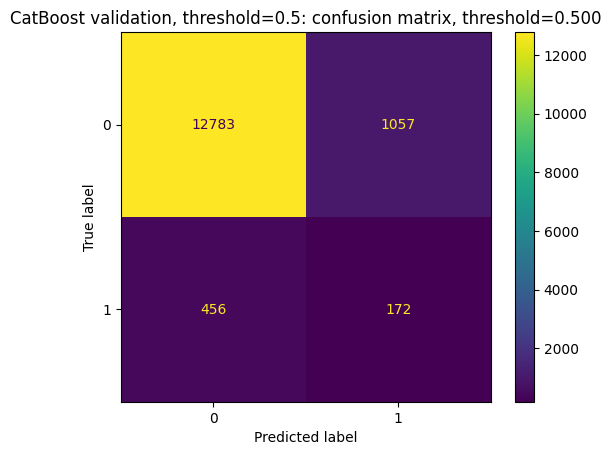

In [82]:
def evaluate_catboost_model(
    model,
    pool,
    y_true,
    threshold=0.5,
    title="CatBoost"
):
    """
    Оценивает CatBoost-модель по готовому Pool.

    Отдельная функция нужна потому, что CatBoost удобнее оценивать через Pool,
    где уже сохранена информация о категориальных признаках.
    """

    y_proba = model.predict_proba(pool)[:, 1]
    y_pred = (y_proba >= threshold).astype("int8")

    metrics = pd.Series({
        "roc_auc": roc_auc_score(y_true, y_proba),
        "average_precision": average_precision_score(y_true, y_proba),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "predicted_positive_rate": y_pred.mean(),
    }, name=title)

    display(metrics.to_frame().T.round(4))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        values_format="d"
    )
    plt.title(f"{title}: confusion matrix, threshold={threshold:.3f}")
    plt.show()

    return metrics, y_proba, y_pred


catboost_valid_metrics_05, catboost_valid_proba, catboost_valid_pred_05 = evaluate_catboost_model(
    catboost_model,
    valid_pool,
    y_valid,
    threshold=0.5,
    title="CatBoost validation, threshold=0.5",
)

### 21.6. Подбор threshold для CatBoost

Как и для Random Forest, threshold подбираем только на validation.

Это не тюнинг модели, а настройка правила принятия решения: какую вероятность считать достаточно высокой, чтобы пометить заказ как рискованный.

,best_threshold,precision,recall,f1
CatBoost best F1 threshold,0.4942,0.1417,0.2962,0.1917


,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
"CatBoost validation, best F1 threshold",0.7222,0.1113,0.1417,0.2962,0.1917,0.6074,0.0908


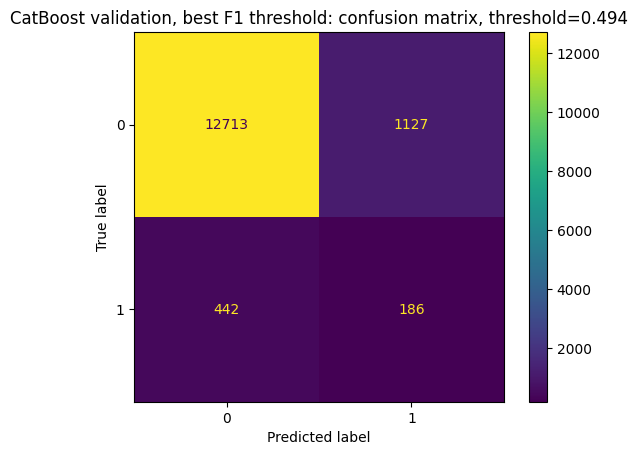

In [83]:
catboost_best_threshold, catboost_threshold_report = find_best_f1_threshold(
    y_valid,
    catboost_valid_proba,
)

display(
    catboost_threshold_report
    .to_frame("CatBoost best F1 threshold")
    .T
    .round(4)
)

catboost_valid_metrics_best, catboost_valid_proba_best, catboost_valid_pred_best = evaluate_catboost_model(
    catboost_model,
    valid_pool,
    y_valid,
    threshold=catboost_best_threshold,
    title="CatBoost validation, best F1 threshold",
)

## 22. Обновлённое сравнение моделей

Теперь сравниваем четыре уровня сложности:

1. `DummyClassifier` — наивный baseline;
2. `Logistic Regression` — линейная модель;
3. `Random Forest` — нелинейный bagging benchmark;
4. `CatBoost` — градиентный бустинг для табличных данных.

Сортируем по `average_precision`, потому что при сильном дисбалансе PR-AUC обычно информативнее, чем accuracy.

In [84]:
model_results_with_catboost = pd.DataFrame([
    dummy_valid_metrics.rename("Dummy baseline"),
    logreg_valid_metrics.rename("Logistic Regression, threshold=0.5"),
    rf_valid_metrics_05.rename("Random Forest, threshold=0.5"),
    rf_valid_metrics_best.rename("Random Forest, best F1 threshold"),
    catboost_valid_metrics_05.rename("CatBoost, threshold=0.5"),
    catboost_valid_metrics_best.rename("CatBoost, best F1 threshold"),
])

model_results_with_catboost = model_results_with_catboost[
    [
        "roc_auc",
        "average_precision",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "predicted_positive_rate",
    ]
]

model_results_with_catboost_sorted = model_results_with_catboost.sort_values(
    by="average_precision",
    ascending=False,
)

display(model_results_with_catboost_sorted.round(4))

,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
"Logistic Regression, threshold=0.5",0.7413,0.1117,0.1235,0.4156,0.1904,0.6409,0.1460
"CatBoost, best F1 threshold",0.7222,0.1113,0.1417,0.2962,0.1917,0.6074,0.0908
"CatBoost, threshold=0.5",0.7222,0.1113,0.1400,0.2739,0.1852,0.5988,0.0849
"Random Forest, best F1 threshold",0.6323,0.0668,0.0716,0.4443,0.1234,0.5915,0.2691
"Random Forest, threshold=0.5",0.6323,0.0668,0.0690,0.4666,0.1203,0.5905,0.2933
Dummy baseline,0.5000,0.0434,0.0000,0.0000,0.0000,0.5000,0.0000


## 23. Feature importance CatBoost

CatBoost даёт встроенную важность признаков.

Это ещё не SHAP, но уже полезный sanity check:

- модель не должна опираться на случайный технический признак;
- важные признаки должны иметь бизнес-смысл;
- можно понять, какие группы признаков дают основной сигнал.

Позже SHAP позволит объяснить влияние признаков точнее и локально для отдельных заказов.

Top-25 признаков CatBoost:


,feature,importance
54,purchase_month,30.386838
52,customer_state,15.449760
15,promised_delivery_days,11.313770
31,seller_known_avg_delay_days_mean,4.773865
38,customer_lng,3.997057
32,seller_known_avg_delay_days_max,3.779591
8,avg_freight,2.683402
14,approval_delay_hours,2.461503
9,max_freight,2.415046
40,seller_customer_distance_km_min,1.968326


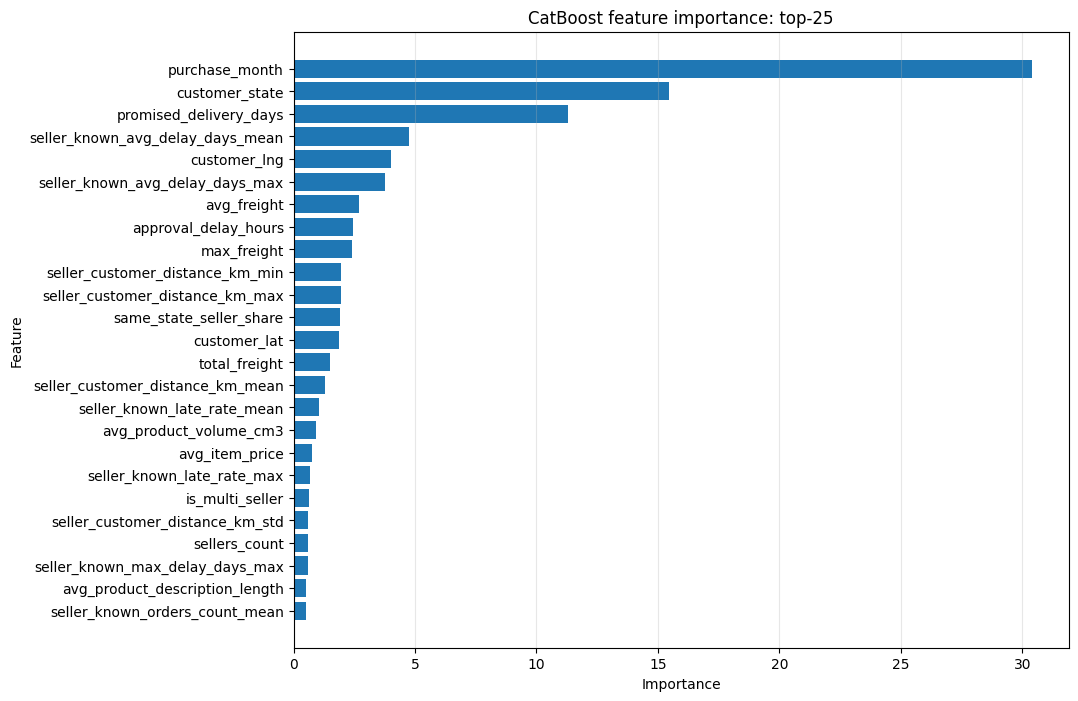

In [85]:
catboost_importance_table = (
    pd.DataFrame({
        "feature": X_train_cb.columns,
        "importance": catboost_model.get_feature_importance(train_pool),
    })
    .sort_values("importance", ascending=False)
)

print("Top-25 признаков CatBoost:")
display(catboost_importance_table.head(25))

plt.figure(figsize=(10, 8))
plt.barh(
    catboost_importance_table.head(25)["feature"][::-1],
    catboost_importance_table.head(25)["importance"][::-1],
)
plt.title("CatBoost feature importance: top-25")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.show()

## Checkpoint после CatBoost + Geo features

На этом этапе ноутбук содержит устойчивое сравнение нескольких моделей:

1. Dummy baseline;
2. Logistic Regression;
3. Random Forest;
4. CatBoost.

В отличие от предыдущей версии, признаки теперь включают не только грубый индикатор `same_state_seller_share`, но и настоящие географические признаки:

- координаты клиента по ZIP prefix;
- среднее расстояние от продавца до клиента;
- минимальное/максимальное расстояние для multi-seller заказов;
- разброс расстояний между продавцами;
- долю продавцов, для которых координаты не удалось восстановить.

Следующий безопасный шаг после проверки этой версии — **leakage-safe historical seller features**. Это должно дать модели более сильный сигнал, чем простая смена алгоритма.


## Checkpoint после leakage-safe seller history features

На этом шаге проект стал сильнее именно с точки зрения портфолио:

- добавлены признаки, которые обычно действительно помогают в delivery-risk задачах;
- исторические признаки построены не простым `groupby` по всей выборке, а с контролем момента доступности outcome;
- текущий `test` по-прежнему не используется для выбора модели или threshold;
- Logistic Regression, RandomForest и CatBoost теперь сравниваются на одном и том же расширенном feature set.

Следующий логичный шаг после проверки этого ноутбука: SHAP для лучшей модели и error analysis по false positives / false negatives.


# 24. Explainability, calibration and error analysis

На этом шаге мы не добавляем новую модель. Мы делаем то, что часто отличает портфолио-проект от обычного Kaggle-ноутбука:

1. переводим модельные score в бизнес-интерпретацию через top-k анализ;
2. проверяем калибровку вероятностей;
3. объясняем CatBoost через SHAP values;
4. разбираем ошибки: false positives и false negatives;
5. только после выбора модели и threshold смотрим финальные метрики на test.

Важно: **test не используется** для подбора threshold, выбора признаков или выбора модели. Все решения выше были приняты на validation.

## 24.1. Выбираем модель-кандидат для интерпретации

По таблице validation видно, что Logistic Regression и CatBoost близки по качеству. Для интерпретации берём **CatBoost** не потому, что он обязан быть финальной моделью, а потому что:

- это более сильная нелинейная модель для табличных данных;
- он работает с категориальными признаками напрямую;
- у CatBoost есть нативный расчёт SHAP values;
- SHAP для CatBoost лучше показывает нелинейные зависимости и взаимодействия признаков.

При этом финальный выбор модели всё равно должен опираться на метрики и бизнес-ограничения, а не на название алгоритма.

In [86]:
# Смотрим финальную validation-таблицу ещё раз.
# Сортировать можно по разным критериям: PR-AUC, F1, recall, precision.
# Для редкого positive class PR-AUC и F1 обычно информативнее accuracy.

display(model_results_with_catboost_sorted.round(4))

selected_model_name = "CatBoost"
selected_threshold = catboost_best_threshold
selected_valid_proba = catboost_valid_proba
selected_valid_pred = (selected_valid_proba >= selected_threshold).astype("int8")

print(f"Selected model for interpretability: {selected_model_name}")
print(f"Selected validation threshold: {selected_threshold:.4f}")

,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
"Logistic Regression, threshold=0.5",0.7413,0.1117,0.1235,0.4156,0.1904,0.6409,0.1460
"CatBoost, best F1 threshold",0.7222,0.1113,0.1417,0.2962,0.1917,0.6074,0.0908
"CatBoost, threshold=0.5",0.7222,0.1113,0.1400,0.2739,0.1852,0.5988,0.0849
"Random Forest, best F1 threshold",0.6323,0.0668,0.0716,0.4443,0.1234,0.5915,0.2691
"Random Forest, threshold=0.5",0.6323,0.0668,0.0690,0.4666,0.1203,0.5905,0.2933
Dummy baseline,0.5000,0.0434,0.0000,0.0000,0.0000,0.5000,0.0000


Selected model for interpretability: CatBoost
Selected validation threshold: 0.4942


## 24.2. Business view: top-k risky orders

Для бизнеса часто важнее не абстрактный ROC-AUC, а вопрос:

> Если операционная команда может проверить только top 5% или top 10% самых рискованных заказов, сколько реальных просрочек там будет?

Поэтому добавим top-k отчёт:

- `selected_orders_share` — какую долю заказов берём в работу;
- `late_rate_in_selected` — фактическая доля просрочек среди выбранных заказов;
- `lift_vs_baseline` — во сколько раз эта доля выше средней доли просрочек;
- `captured_late_share` — какую долю всех просрочек validation мы поймали.

In [87]:
def top_k_lift_report(y_true, y_proba, k_values=(0.01, 0.05, 0.10, 0.20, 0.30)):
    # Оценивает качество модели как инструмента приоритизации.
    scored = pd.DataFrame({
        "y_true": np.asarray(y_true).astype(int),
        "y_proba": np.asarray(y_proba).astype(float),
    }).sort_values("y_proba", ascending=False).reset_index(drop=True)

    baseline_late_rate = scored["y_true"].mean()
    total_late = scored["y_true"].sum()

    rows = []

    for k in k_values:
        n_selected = max(1, int(np.ceil(len(scored) * k)))
        selected = scored.head(n_selected)

        late_count = selected["y_true"].sum()
        late_rate = selected["y_true"].mean()

        rows.append({
            "selected_orders_share": k,
            "selected_orders_count": n_selected,
            "late_rate_in_selected": late_rate,
            "baseline_late_rate": baseline_late_rate,
            "lift_vs_baseline": late_rate / baseline_late_rate if baseline_late_rate > 0 else np.nan,
            "captured_late_share": late_count / total_late if total_late > 0 else np.nan,
        })

    return pd.DataFrame(rows)


catboost_topk_report = top_k_lift_report(
    y_valid,
    catboost_valid_proba,
)

display(catboost_topk_report.round(4))

,selected_orders_share,selected_orders_count,late_rate_in_selected,baseline_late_rate,lift_vs_baseline,captured_late_share
0,0.01,145,0.1862,0.0434,4.2899,0.0430
1,0.05,724,0.1561,0.0434,3.5957,0.1799
2,0.10,1447,0.1348,0.0434,3.1047,0.3105
3,0.20,2894,0.1026,0.0434,2.3643,0.4729
4,0.30,4341,0.0852,0.0434,1.9636,0.5892


## 24.3. Calibration curve

ROC-AUC и PR-AUC оценивают ранжирование: насколько хорошо модель ставит рискованные заказы выше нерискованных.

Но если мы хотим использовать score как вероятность, нужна калибровка:

> Среди заказов, которым модель дала риск около 20%, действительно должно быть около 20% просрочек.

Для операционных решений это важно: плохо откалиброванная модель может хорошо ранжировать, но вводить бизнес в заблуждение конкретными вероятностями.

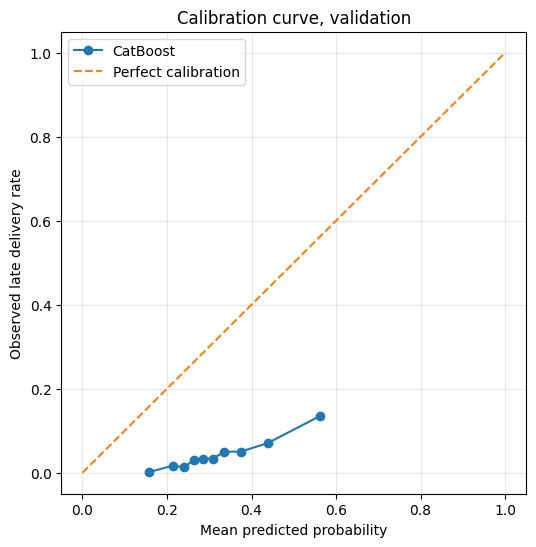

In [88]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_valid,
    catboost_valid_proba,
    n_bins=10,
    strategy="quantile",
)

plt.figure(figsize=(6, 6))
plt.plot(prob_pred, prob_true, marker="o", label="CatBoost")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.title("Calibration curve, validation")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed late delivery rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 24.4. SHAP для CatBoost

SHAP показывает вклад каждого признака в предсказание модели.

Для каждого заказа:

```text
prediction = base_value + sum(feature_shap_values)
```

- положительный SHAP value двигает предсказание в сторону большей вероятности просрочки;
- отрицательный SHAP value двигает предсказание в сторону меньшей вероятности просрочки;
- `mean(abs(SHAP))` показывает глобальную важность признака.

Для скорости считаем SHAP не на всей validation-выборке, а на сэмпле. Это нормальная практика: SHAP может быть дорогим на больших данных.

In [89]:
# Сэмпл для SHAP: достаточно большой, чтобы увидеть стабильную картину,
# но не слишком большой, чтобы ноутбук быстро выполнялся.
shap_sample_size = min(2000, len(X_valid_cb))

X_valid_cb_shap = X_valid_cb.sample(
    n=shap_sample_size,
    random_state=42,
)

y_valid_shap = y_valid.loc[X_valid_cb_shap.index]

shap_pool = Pool(
    X_valid_cb_shap,
    label=y_valid_shap,
    cat_features=cat_feature_indices,
)

# CatBoost возвращает матрицу размера n_objects x (n_features + 1).
# Последняя колонка — expected value / base value.
catboost_shap_values = catboost_model.get_feature_importance(
    shap_pool,
    type="ShapValues",
)

shap_feature_values = catboost_shap_values[:, :-1]
shap_expected_values = catboost_shap_values[:, -1]

shap_importance = (
    pd.DataFrame({
        "feature": X_valid_cb_shap.columns,
        "mean_abs_shap": np.abs(shap_feature_values).mean(axis=0),
        "mean_shap": shap_feature_values.mean(axis=0),
    })
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

display(shap_importance.head(25).round(5))

,feature,mean_abs_shap,mean_shap
0,purchase_month,0.50913,-0.50913
1,customer_state,0.26914,-0.05149
2,promised_delivery_days,0.22866,-0.02155
3,seller_known_avg_delay_days_mean,0.10105,0.06746
4,avg_freight,0.07288,0.00067
5,seller_known_avg_delay_days_max,0.06790,0.04373
6,customer_lng,0.06249,-0.00790
7,approval_delay_hours,0.05863,0.02149
8,max_freight,0.05411,-0.00438
9,same_state_seller_share,0.03741,0.00754


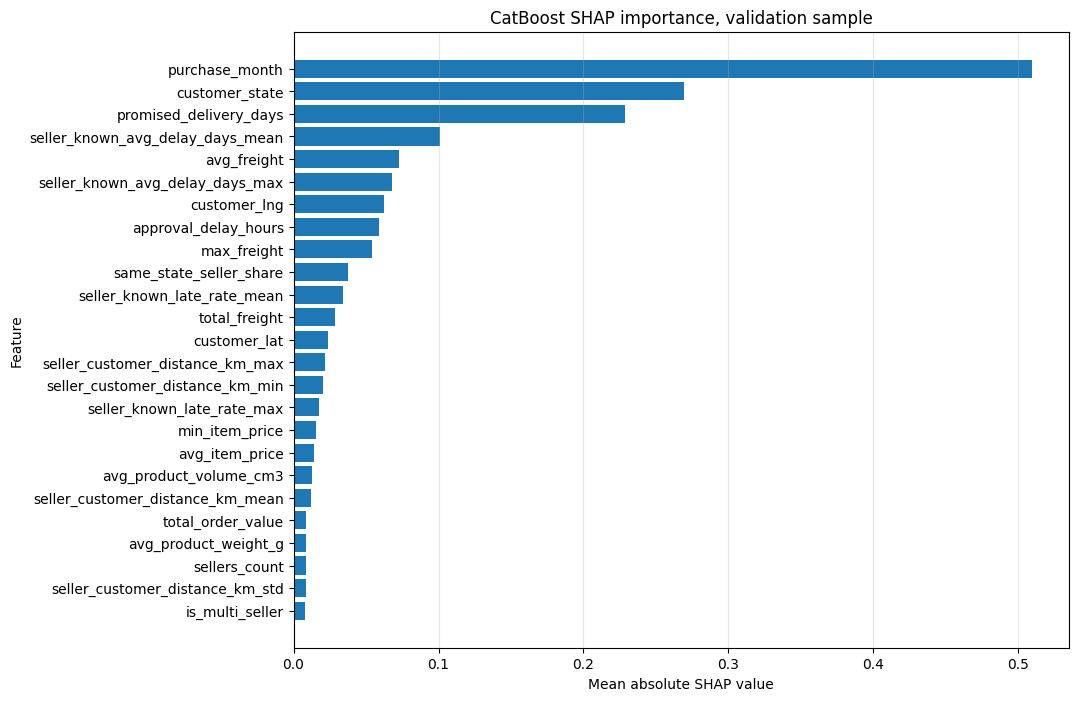

In [90]:
plt.figure(figsize=(10, 8))

plot_data = shap_importance.head(25).sort_values("mean_abs_shap")

plt.barh(
    plot_data["feature"],
    plot_data["mean_abs_shap"],
)

plt.title("CatBoost SHAP importance, validation sample")
plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.show()

### Optional SHAP beeswarm

Если библиотека `shap` установлена, строим beeswarm-график. Если нет — ноутбук не падает, потому что основная SHAP-таблица выше уже рассчитана нативными средствами CatBoost.

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


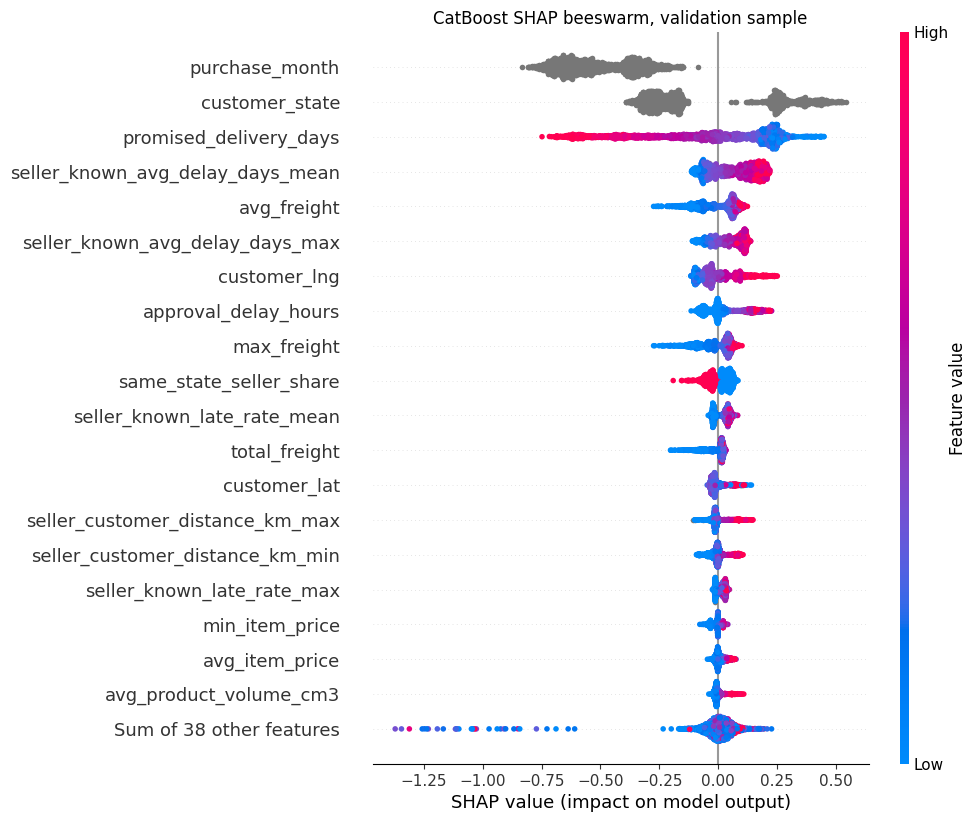

In [91]:
try:
    import shap

    shap_explanation = shap.Explanation(
        values=shap_feature_values,
        base_values=shap_expected_values,
        data=X_valid_cb_shap,
        feature_names=list(X_valid_cb_shap.columns),
    )

    shap.plots.beeswarm(
        shap_explanation,
        max_display=20,
        show=False,
    )
    plt.title("CatBoost SHAP beeswarm, validation sample")
    plt.show()

except ImportError:
    print("Библиотека shap не установлена. Установить можно так: pip install shap")

except Exception as error:
    print("SHAP beeswarm не построен, но нативные SHAP values CatBoost рассчитаны выше.")
    print(f"Причина: {type(error).__name__}: {error}")

## 24.5. Error analysis: false positives and false negatives

Теперь смотрим не только на агрегированные метрики, но и на то, **где именно модель ошибается**.

Нас интересуют два типа ошибок:

- **False Positive**: модель предупредила о риске задержки, но заказ был доставлен вовремя. Это лишняя операционная нагрузка.
- **False Negative**: модель не предупредила, но заказ реально задержался. Это потенциально худший тип ошибки для клиентского опыта.

Такой анализ нужен, чтобы понять: модель ошибается случайно или у ошибок есть понятные сегменты — регионы, категории, дальние доставки, продавцы без истории и т.д.

In [92]:
valid_error_df = valid_df.copy()
valid_error_df["catboost_proba"] = catboost_valid_proba
valid_error_df["catboost_pred"] = selected_valid_pred

valid_error_df["error_type"] = np.select(
    [
        (valid_error_df[target_column] == 1) & (valid_error_df["catboost_pred"] == 1),
        (valid_error_df[target_column] == 0) & (valid_error_df["catboost_pred"] == 1),
        (valid_error_df[target_column] == 1) & (valid_error_df["catboost_pred"] == 0),
        (valid_error_df[target_column] == 0) & (valid_error_df["catboost_pred"] == 0),
    ],
    ["TP", "FP", "FN", "TN"],
    default="unknown",
)

error_type_summary = (
    valid_error_df["error_type"]
    .value_counts()
    .rename_axis("error_type")
    .reset_index(name="orders")
)

error_type_summary["share"] = error_type_summary["orders"] / len(valid_error_df)

display(error_type_summary.round(4))

,error_type,orders,share
0,TN,12713,0.8787
1,FP,1127,0.0779
2,FN,442,0.0306
3,TP,186,0.0129


In [93]:
# Сравниваем медианные значения ключевых признаков по типам ошибок.
# Это помогает увидеть, например, что FN чаще возникают в конкретных условиях.

analysis_numeric_features = [
    "catboost_proba",
    "promised_delivery_days",
    "approval_delay_hours",
    "seller_customer_distance_km_mean",
    "seller_known_orders_count_mean",
    "seller_known_late_rate_mean",
    "seller_known_avg_delay_days_mean",
    "seller_history_available_share",
    "total_order_value",
    "items_count",
    "avg_product_weight_g",
]

available_analysis_numeric_features = [
    column for column in analysis_numeric_features
    if column in valid_error_df.columns
]

error_numeric_profile = (
    valid_error_df
    .groupby("error_type")[available_analysis_numeric_features]
    .median()
    .T
)

display(error_numeric_profile.round(4))

error_type,FN,FP,TN,TP
catboost_proba,0.3323,0.5546,0.2851,0.5650
promised_delivery_days,20.0000,27.0000,25.0000,25.0000
approval_delay_hours,0.5543,1.8433,0.4625,6.8047
seller_customer_distance_km_mean,431.1618,1349.5752,362.9696,1459.6514
seller_known_orders_count_mean,63.0000,89.0000,75.0000,59.5000
seller_known_late_rate_mean,0.0619,0.0800,0.0603,0.0759
seller_known_avg_delay_days_mean,-10.6667,-10.1366,-11.0455,-10.1463
seller_history_available_share,1.0000,1.0000,1.0000,1.0000
total_order_value,112.8650,138.6000,108.0700,140.8950
items_count,1.0000,1.0000,1.0000,1.0000


In [94]:
def segment_error_report(df, segment_column, min_orders=80):
    # Строит отчёт по ошибкам модели внутри сегментов.
    # min_orders нужен, чтобы не делать выводы по сегментам из 2-3 заказов.
    if segment_column not in df.columns:
        raise ValueError(f"Column {segment_column!r} not found")

    report = (
        df
        .groupby(segment_column)
        .agg(
            orders=("order_id", "count"),
            late_rate=(target_column, "mean"),
            avg_predicted_risk=("catboost_proba", "mean"),
            alerts=("catboost_pred", "sum"),
            fp_count=("error_type", lambda values: (values == "FP").sum()),
            fn_count=("error_type", lambda values: (values == "FN").sum()),
            tp_count=("error_type", lambda values: (values == "TP").sum()),
        )
        .query("orders >= @min_orders")
        .reset_index()
    )

    report["alert_rate"] = report["alerts"] / report["orders"]
    report["fp_share_of_segment"] = report["fp_count"] / report["orders"]
    report["fn_share_of_segment"] = report["fn_count"] / report["orders"]

    return report.sort_values(
        ["fn_count", "late_rate"],
        ascending=False,
    )


for segment_column in ["customer_state", "main_product_category", "purchase_month"]:
    print(f"\nSegment analysis: {segment_column}")
    display(
        segment_error_report(valid_error_df, segment_column)
        .head(15)
        .round(4)
    )


Segment analysis: customer_state


,customer_state,orders,late_rate,avg_predicted_risk,alerts,fp_count,fn_count,tp_count,alert_rate,fp_share_of_segment,fn_share_of_segment
15,SP,6524,0.0267,0.2668,5,4,173,1,0.0008,0.0006,0.0265
6,MG,1644,0.0444,0.2662,1,1,73,0,0.0006,0.0006,0.0444
12,RJ,1761,0.0443,0.3856,333,299,44,34,0.1891,0.1698,0.0250
0,BA,496,0.1593,0.4758,231,183,31,48,0.4657,0.3690,0.0625
11,PR,722,0.0319,0.2511,0,0,23,0,0.0000,0.0000,0.0319
13,RS,711,0.0253,0.3550,37,36,17,1,0.0520,0.0506,0.0239
2,DF,320,0.0469,0.2659,0,0,15,0,0.0000,0.0000,0.0469
3,ES,277,0.1227,0.4438,90,70,14,20,0.3249,0.2527,0.0505
14,SC,509,0.0295,0.3749,55,52,12,3,0.1081,0.1022,0.0236
9,PA,114,0.1404,0.3803,10,4,10,6,0.0877,0.0351,0.0877



Segment analysis: main_product_category


,main_product_category,orders,late_rate,avg_predicted_risk,alerts,fp_count,fn_count,tp_count,alert_rate,fp_share_of_segment,fn_share_of_segment
2,beleza_saude,1518,0.0626,0.3265,151,121,65,30,0.0995,0.0797,0.0428
24,relogios_presentes,1177,0.0535,0.3235,134,114,43,20,0.1138,0.0969,0.0365
4,cama_mesa_banho,1351,0.0348,0.3015,93,83,37,10,0.0688,0.0614,0.0274
19,moveis_decoracao,875,0.0446,0.3221,85,78,32,7,0.0971,0.0891,0.0366
26,utilidades_domesticas,1031,0.0407,0.3129,80,66,28,14,0.0776,0.0640,0.0272
11,esporte_lazer,927,0.0464,0.3197,94,77,26,17,0.1014,0.0831,0.0280
0,automotivo,621,0.0596,0.3325,63,50,24,13,0.1014,0.0805,0.0386
14,informatica_acessorios,857,0.0327,0.3055,70,62,20,8,0.0817,0.0723,0.0233
22,perfumaria,383,0.0496,0.3045,21,19,17,2,0.0548,0.0496,0.0444
13,ferramentas_jardim,456,0.0504,0.3164,42,35,16,7,0.0921,0.0768,0.0351



Segment analysis: purchase_month


,purchase_month,orders,late_rate,avg_predicted_risk,alerts,fp_count,fn_count,tp_count,alert_rate,fp_share_of_segment,fn_share_of_segment
1,5,6749,0.0656,0.3132,482,389,350,93,0.0714,0.0576,0.0519
0,4,3585,0.0368,0.3732,682,604,54,78,0.1902,0.1685,0.0151
2,6,4134,0.0128,0.2778,149,134,38,15,0.0360,0.0324,0.0092


## 24.6. Local explanations for individual orders

Глобальный SHAP отвечает на вопрос:

> Какие признаки важны в среднем?

Локальный SHAP отвечает на другой вопрос:

> Почему модель дала такой score конкретному заказу?

Ниже берём по одному примеру:

- high-confidence True Positive — модель правильно нашла рискованный заказ;
- high-risk False Positive — модель перестраховалась;
- False Negative с самым высоким score среди пропущенных — модель почти поймала просрочку, но score оказался ниже threshold.

In [95]:
def explain_single_order_with_catboost_shap(row_index, top_n=12):
    # Возвращает top признаков, которые сильнее всего повлияли на CatBoost prediction.
    x_one = X_valid_cb.loc[[row_index]]

    one_pool = Pool(
        x_one,
        cat_features=cat_feature_indices,
    )

    one_shap_values = catboost_model.get_feature_importance(
        one_pool,
        type="ShapValues",
    )[0]

    feature_shap_values = one_shap_values[:-1]
    base_value = one_shap_values[-1]

    local_explanation = (
        pd.DataFrame({
            "feature": X_valid_cb.columns,
            "feature_value": x_one.iloc[0].astype(str).values,
            "shap_value": feature_shap_values,
            "abs_shap": np.abs(feature_shap_values),
        })
        .sort_values("abs_shap", ascending=False)
        .head(top_n)
    )

    return base_value, local_explanation


example_specs = {
    "High-confidence True Positive": (
        valid_error_df
        .query("error_type == 'TP'")
        .sort_values("catboost_proba", ascending=False)
    ),
    "High-risk False Positive": (
        valid_error_df
        .query("error_type == 'FP'")
        .sort_values("catboost_proba", ascending=False)
    ),
    "Borderline False Negative": (
        valid_error_df
        .query("error_type == 'FN'")
        .sort_values("catboost_proba", ascending=False)
    ),
}

example_columns = [
    "order_id",
    target_column,
    "catboost_proba",
    "catboost_pred",
    "error_type",
    "customer_state",
    "main_product_category",
    "promised_delivery_days",
    "seller_customer_distance_km_mean",
    "seller_known_late_rate_mean",
    "seller_history_available_share",
]

example_columns = [
    column for column in example_columns
    if column in valid_error_df.columns
]

for title, candidates in example_specs.items():
    print("\n" + "=" * 90)
    print(title)

    if len(candidates) == 0:
        print("Нет примеров такого типа ошибок/решений на validation при выбранном threshold.")
        continue

    row_index = candidates.index[0]

    display(valid_error_df.loc[[row_index], example_columns].round(4))

    base_value, local_explanation = explain_single_order_with_catboost_shap(
        row_index,
        top_n=12,
    )

    print(f"Base value: {base_value:.4f}")
    display(local_explanation.round(5))


High-confidence True Positive


,order_id,late_delivery,catboost_proba,catboost_pred,error_type,customer_state,main_product_category,promised_delivery_days,seller_customer_distance_km_mean,seller_known_late_rate_mean,seller_history_available_share
85949,8a5dedf23891883d88a7f6e28b880c8f,1,0.7566,1,TP,MA,utilidades_domesticas,22,2263.4149,0.05,1.0


Base value: -0.3814


,feature,feature_value,shap_value,abs_shap
52,customer_state,MA,0.49090,0.49090
54,purchase_month,4,-0.32003,0.32003
15,promised_delivery_days,22,0.26844,0.26844
31,seller_known_avg_delay_days_mean,-7.3,0.21453,0.21453
41,seller_customer_distance_km_max,2263.4148545887087,0.14386,0.14386
32,seller_known_avg_delay_days_max,-7.3,0.11995,0.11995
8,avg_freight,24.48,0.09004,0.09004
37,customer_lat,-2.499473226500051,0.08524,0.08524
40,seller_customer_distance_km_min,2263.4148545887087,0.08462,0.08462
9,max_freight,24.48,0.07681,0.07681



High-risk False Positive


,order_id,late_delivery,catboost_proba,catboost_pred,error_type,customer_state,main_product_category,promised_delivery_days,seller_customer_distance_km_mean,seller_known_late_rate_mean,seller_history_available_share
66540,35b0513eaf7a477cdb93469b7b4a3d6c,0,0.7737,1,FP,PI,utilidades_domesticas,23,2095.1537,0.1085,1.0


Base value: -0.3814


,feature,feature_value,shap_value,abs_shap
52,customer_state,PI,0.48126,0.48126
54,purchase_month,4,-0.31527,0.31527
15,promised_delivery_days,23,0.21821,0.21821
31,seller_known_avg_delay_days_mean,-9.472868217054264,0.20916,0.20916
41,seller_customer_distance_km_max,2095.153702631722,0.13879,0.13879
32,seller_known_avg_delay_days_max,-9.472868217054264,0.12722,0.12722
38,customer_lng,-42.766260952103636,0.09714,0.09714
40,seller_customer_distance_km_min,2095.153702631722,0.08677,0.08677
8,avg_freight,27.74,0.08629,0.08629
37,customer_lat,-5.069582897257019,0.08449,0.08449



Borderline False Negative


,order_id,late_delivery,catboost_proba,catboost_pred,error_type,customer_state,main_product_category,promised_delivery_days,seller_customer_distance_km_mean,seller_known_late_rate_mean,seller_history_available_share
62397,15327faedc0b46ed8e761a6828b9e039,1,0.4924,0,FN,RJ,esporte_lazer,20,507.8201,0.0567,1.0


Base value: -0.3814


,feature,feature_value,shap_value,abs_shap
54,purchase_month,5,-0.80492,0.80492
52,customer_state,RJ,0.44537,0.44537
15,promised_delivery_days,20,0.21613,0.21613
38,customer_lng,-41.944338149018726,0.10982,0.10982
8,avg_freight,18.36,0.07290,0.07290
31,seller_known_avg_delay_days_mean,-11.69047619047619,0.06365,0.06365
9,max_freight,18.36,0.05463,0.05463
26,same_state_seller_share,0.0,0.04897,0.04897
29,seller_known_late_rate_mean,0.05665024630541872,0.04893,0.04893
32,seller_known_avg_delay_days_max,-11.69047619047619,0.04266,0.04266


## 24.7. Final test evaluation

Теперь можно один раз посмотреть test:

- модели уже обучены;
- threshold выбран на validation;
- SHAP и error analysis делались на validation;
- test не участвовал в принятии решений.

Это имитирует реальную ситуацию: мы приняли решение на исторических данных и проверяем, как оно переносится на будущий период.

,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
"Random Forest test, validation-selected threshold",0.4296,0.0374,0.0338,0.1971,0.0577,0.4726,0.2496


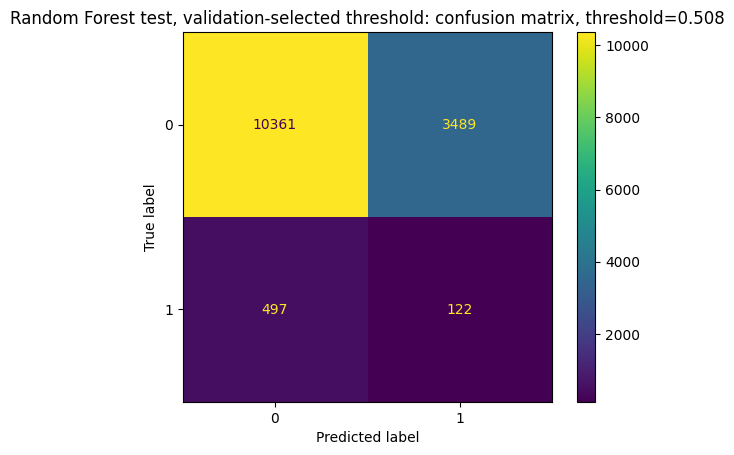

,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
"CatBoost test, validation-selected threshold",0.6133,0.058,0.0628,0.1405,0.0868,0.5234,0.0957


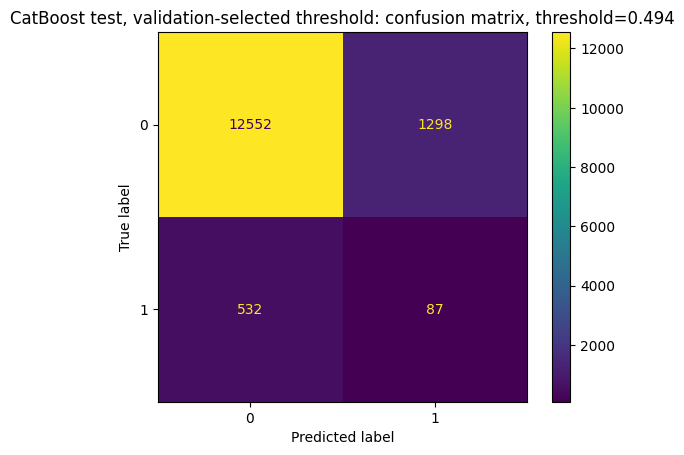

,roc_auc,average_precision,precision,recall,f1,balanced_accuracy,predicted_positive_rate
Logistic Regression test,0.6634,0.0738,0.0859,0.1874,0.1178,0.5491,0.0934
CatBoost test,0.6133,0.0580,0.0628,0.1405,0.0868,0.5234,0.0957
Random Forest test,0.4296,0.0374,0.0338,0.1971,0.0577,0.4726,0.2496


In [96]:
rf_test_metrics_best, rf_test_proba, rf_test_pred = evaluate_classifier(
    rf_model,
    X_test,
    y_test,
    threshold=rf_best_threshold,
    title="Random Forest test, validation-selected threshold",
)

catboost_test_metrics_best, catboost_test_proba, catboost_test_pred = evaluate_catboost_model(
    catboost_model,
    test_pool,
    y_test,
    threshold=catboost_best_threshold,
    title="CatBoost test, validation-selected threshold",
)

final_test_results = pd.DataFrame([
    logreg_test_metrics.rename("Logistic Regression test"),
    rf_test_metrics_best.rename("Random Forest test"),
    catboost_test_metrics_best.rename("CatBoost test"),
])

final_test_results = final_test_results[
    [
        "roc_auc",
        "average_precision",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
        "predicted_positive_rate",
    ]
]

display(final_test_results.sort_values("average_precision", ascending=False).round(4))

## Checkpoint после SHAP и error analysis

На этом этапе проект уже содержит важные элементы сильного портфолио-проекта:

- несколько моделей: Dummy, Logistic Regression, RandomForest, CatBoost;
- временной split вместо случайного;
- leakage-safe feature engineering;
- geo distance;
- historical seller reliability features;
- threshold tuning на validation;
- top-k business report;
- calibration check;
- SHAP global explanations;
- SHAP local explanations;
- error analysis по FP/FN;
- финальную test-проверку после выбора модели и threshold.

Следующий шаг для ещё более сильной версии — не новая модель, а упаковка проекта:

```text
README.md
requirements.txt
src/features.py
src/train.py
src/evaluate.py
reports/final_report.md
```

Это превратит ноутбук из анализа в полноценный репозиторий для портфолио.